# NGC 4151 DC4 paper figures: source catalog and isolated CPL + PL

**Archived combined version.** Use `NGC4151_DC4_Paper_Figure1_SourceCatalog.ipynb` for the catalog figure and `NGC4151_DC4_Paper_Figure2_Isolated_CPLPL.ipynb` for the isolated figure. Those focused notebooks contain the revised CPL index bound, catalog covariance band, and isolated SED pseudocount. This combined notebook is retained only for its older six-month scenario and saved outputs.

Four white-background figures are produced: the three-month SC fit on the **unaltered full DC4 mock**, a matched three-month SC fit on the **updated 0.30 mock**, a six-month **2× exposure forecast** of that SC fit, and a 24-month isolated CPL + PL exposure forecast from the three-month NGC 4151 source-plus-background histogram with an injected PL/CPL differential-flux ratio of 0.30 at 200 keV. Each SC fit includes the other 70 catalog sources. The original and updated SC fits use the same catalog, GTI, response, background template, and CPL parameter bounds. Figure 1 bins the original DC4 NGC 4151 event FITS for its three-month isolated comparison; Figure 2 uses the separately modified 0.30 source histogram. Each independent SED uses the 10 native 0.1–10 MeV response bins with BinnedSED's default E^-2 shape. Profile likelihood supplies detections and TS ≥ 1 limits; only TS < 1 upper limits use threeML Bayesian sampling.

Run cells in order. The six-month SC cell restores the three-month catalog data and responses after its fit. The first figure compares three-month fits, including its isolated NGC 4151 CPL curve. The second figure repeats the selected three-month isolated source, instrumental background, and pointing livetime eight times for a 24-month forecast, not a new simulation. The six-month scenario repeats the same three-month counts and pointing at twice the exposure; it is not a separate six-month simulation. The response cache is large, and the catalog fits can take time.

All figures display with a white background and save white PDF and PNG files to `~/Library/CloudStorage/OneDrive-ClemsonUniversity/Papers/DC4_Paper`.


In [18]:
from pathlib import Path
from copy import deepcopy
import sys
import gc
import hashlib

import astropy.units as u
from astropy.coordinates import SkyCoord
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from IPython.display import display

from astromodels import (
    Cutoff_powerlaw, ExtendedSource, PointSource, Parameter, Powerlaw, Model, load_model,
)
from histpy import Histogram
from threeML import DataList, JointLikelihood, BayesianAnalysis
from threeML.minimizer.minimization import FitFailed, CannotComputeCovariance
from threeML.exceptions.custom_exceptions import BadCovariance
from cosipy.threeml import BinnedSED
from dataclasses import dataclass
from scipy.optimize import brentq, minimize

from cosipy import BinnedData
from cosipy.background_estimation import FreeNormBinnedBackground
from cosipy.data_io import EmCDSBinnedData
from cosipy.event_selection import GoodTimeInterval
from cosipy.interfaces import ThreeMLPluginInterface
from cosipy.response import (
    BinnedInstrumentResponse,
    BinnedThreeMLModelFolding,
    BinnedThreeMLPointSourceResponse,
    BinnedThreeMLExtendedSourceResponse,
    ExtendedSourceResponse,
)
from cosipy.response.FullDetectorResponse import FullDetectorResponse
from cosipy.spacecraftfile import SpacecraftHistory
from cosipy.statistics import PoissonLikelihood
from cosipy.threeml.custom_functions import GalpropHealpixModel, SpecFromDat  # noqa: F401


# DC4 recipe interpretation stays in this tutorial; reusable calculations live in cosipy.
import json
import yaml
from astropy.io import fits
from cosipy.response.temporal_profile import LightcurveProfile
from cosipy.response.threeml_temporal_response import (
    ZeroPointSourceResponse, ComponentPointSourceResponse,
    make_weighted_point_source_response,
)
from cosipy.util.megalib import megalib_map_to_galprop_fits

from threeML.plugin_prototype import PluginPrototype
from astromodels import Uniform_prior


## Shared catalog, spatial-template, and histogram helpers


In [19]:
def load_recipe(path, catalog_path, model):
    # A relocated recipe may be supplied in memory; retain the same validation.
    recipe = deepcopy(path) if isinstance(path, dict) else json.loads(Path(path).read_text())
    if recipe.get('schema') != 'dc4-component-lightcurve-response-v1':
        raise ValueError("Unsupported temporal-response recipe schema")
    if Path(recipe['catalog']).resolve() != Path(catalog_path).resolve():
        raise ValueError("The response recipe belongs to a different catalog")
    if recipe['selection'] not in {'full', 'NGC4151_GTI'} or recipe['time_basis'] != 'elapsed':
        raise ValueError("Expected a full-observation or NGC4151 GTI elapsed-time catalog")
    if set(row['source'] for row in recipe['components']) != set(model.sources):
        raise ValueError("Recipe and catalog source lists differ")
    if any(row['selection'] != recipe['selection'] for row in recipe['components']):
        raise ValueError("Mixed selections in response recipe")
    keys = [(r['source'], r['component']) for r in recipe['components']]
    if len(set(keys)) != len(keys):
        raise ValueError("Duplicate source/component recipe entries")
    return recipe


def component_name(source, label):
    if label in source.components:
        return label
    # v1 recipes store MEGAlib labels rather than astromodels component names.
    crab_names = {'Crab_Nebula': 'nebula', 'Crab_P1': 'peak1',
                  'Crab_Brg': 'bridge', 'Crab_P2': 'peak2'}
    if source.name == 'crab' and crab_names.get(label) in source.components:
        return crab_names[label]
    raise ValueError(f"Unknown temporal component {source.name}/{label}")


def make_temporal_responses(model, recipe, base_history, gti, data,
                            instrument_response, detector_response,
                            exposure_multiplier=1., full_history=None):
    """Build per-source/component responses from the unscaled GTI history.

    Validate temporal factors over the CATALOG selection, which can differ
    from the analysis GTI. Full catalogs require the original full_history:
    response weights remain L(t)/mean_full while exposure is GTI restricted.
    Exposure repetitions multiply response livetimes, not fluxes.
    Responses are computed lazily by cosipy and reused throughout fitting.
    """
    if not np.isfinite(exposure_multiplier) or exposure_multiplier <= 0:
        raise ValueError("Exposure multiplier must be finite and positive")
    starts, stops = np.asarray(gti.tstart_list.unix), np.asarray(gti.tstop_list.unix)
    duration = float(np.sum(stops-starts))
    if duration <= 0 or np.any(stops <= starts):
        raise ValueError("The analysis GTI must have positive duration")
    catalog_selection = recipe.get('selection', 'NGC4151_GTI')
    if catalog_selection == 'full':
        if full_history is None:
            raise ValueError("Full-observation catalogs require the original full_history")
        reference_starts = np.array([full_history.obstime[0].unix])
        reference_stops = np.array([full_history.obstime[-1].unix])
        if np.any(starts < reference_starts[0]-1e-5) or np.any(stops > reference_stops[0]+1e-5):
            raise ValueError("The analysis GTI extends beyond the catalog observation")
    elif catalog_selection == 'NGC4151_GTI':
        reference_starts, reference_stops = starts, stops
    else:
        raise ValueError(f"Unsupported catalog selection: {catalog_selection}")
    reference_duration = float(np.sum(reference_stops-reference_starts))
    if not np.isfinite(reference_duration) or reference_duration <= 0:
        raise ValueError("Invalid catalog reference duration")
    history_starts, history_stops = base_history.intervals_tstart.unix, base_history.intervals_tstop.unix
    rows_by_source = {}
    for row in recipe['components']:
        rows_by_source.setdefault(row['source'], []).append(row)
    overrides, diagnostics = {}, []
    for key, rows in rows_by_source.items():
        source = model.sources[key]
        for row in rows:
            if not np.isclose(row['selected seconds'], reference_duration, rtol=0., atol=1e-4):
                raise ValueError(f"Reference duration differs from the catalog: {key}")
        if not any(row['lightcurve'] for row in rows):
            continue
        if not isinstance(source, PointSource):
            raise NotImplementedError(f"A temporal extended response is required for {key}")
        if any(r['component'] == 'all' for r in rows) and len(rows) != 1:
            raise ValueError(f"Invalid component grouping for {key}")
        component_responses = {}
        for row in rows:
            applied = float(row['applied factor'])
            if not np.isfinite(applied) or applied <= 0:
                raise ValueError(f"Invalid applied factor for {key}")
            if row['lightcurve']:
                profile = LightcurveProfile.from_dat(
                    row['lightcurve'], expected_sha256=row['lightcurve sha256'],
                    repeating=row['repeating'], mode=row['normalization mode'],
                    bins=int(row['simulation bins']),
                )
                mean = float(profile.integral(reference_starts, reference_stops).sum()/reference_duration)
                gti_mean = float(profile.integral(starts, stops).sum()/duration)
                weights = profile.response_weights(history_starts, history_stops, applied)
                del profile
            else:
                mean, gti_mean, weights = 1., 1., np.ones(base_history.nintervals)
            if not np.isclose(mean, row['time factor'], rtol=1e-8, atol=1e-14):
                raise ValueError(f"Temporal factor differs from catalog for {key}/{row['component']}")
            if not np.isclose(applied, max(mean, 1e-30), rtol=1e-8, atol=0.):
                raise ValueError(f"Applied factor differs from catalog for {key}")
            weighted_live = base_history.livetime * weights * exposure_multiplier
            response = make_weighted_point_source_response(
                base_history, weights, data, instrument_response, detector_response,
                exposure_multiplier=exposure_multiplier,
            )
            diagnostics.append({'source': key, 'component': row['component'],
                                'normalization mode': row['normalization mode'],
                                'simulation bins': row['simulation bins'],
                                'catalog selection': catalog_selection,
                                'catalog time factor': mean,
                                'analysis GTI time factor': gti_mean,
                                'response denominator': applied,
                                'weighted response seconds': float(weighted_live.to_value(u.s).sum())})
            if row['component'] == 'all':
                overrides[key] = response
            else:
                name = component_name(source, row['component'])
                if name in component_responses:
                    raise ValueError(f"Duplicate mapped component for {key}/{name}")
                component_responses[name] = response
        if component_responses:
            if set(component_responses) != set(source.components):
                raise ValueError(f"Recipe does not cover all components of {key}")
            overrides[key] = ComponentPointSourceResponse(component_responses)
    return overrides, diagnostics


In [20]:
SPATIAL_TEMPLATE_NSIDE = 8
SPATIAL_TEMPLATE_FORMAT_TAG = "perMeV_v3"
SPATIAL_DEFINITIONS = {'positrons_26al_line': ('DC3', 'Positrons_from_26Al_line'),
 'positrons_26al_cont': ('DC3', 'Positrons_from_26Al_cont'),
 'positrons_44ti_line': ('DC3', 'Positrons_from_44Ti_line'),
 'positrons_44ti_cont': ('DC3', 'Positrons_from_44Ti_cont'),
 'narrow_bulge_511': ('DC3', 'NB_511'),
 'broad_bulge_511': ('DC3', 'BB_511'),
 'vela_snr_511': ('DC3', 'Vela_SNR_511'),
 'al26_ne2001': ('DC3', '26Al_NE2001'),
 'fe60_ne2001': ('DC3', '60Fe_NE2001'),
 'positrons_thin_disk_cont': ('DC4', 'Positrons_Thin_Disk_cont'),
 'positrons_thin_disk_line': ('DC4', 'Positrons_Thin_Disk_line')}

def resolve_source_asset(source_definition, filename):
    path = source_definition.parent / filename
    candidates = [path, Path(f"{path}.gz")]
    for candidate in candidates:
        if candidate.exists():
            return candidate.resolve()
    raise FileNotFoundError(
        f"Could not resolve {filename!r} next to {source_definition}"
    )


def parse_megalib_blocks(source_definition):
    # Return one property dictionary per DataChallenge.Source block.
    blocks = []
    by_megalib_name = {}
    for raw_line in source_definition.read_text().splitlines():
        line = raw_line.split("#", 1)[0].strip()
        if not line:
            continue
        tokens = line.split()
        if tokens[:1] == ["DataChallenge.Source"]:
            megalib_name = tokens[1]
            block = {"_name": megalib_name}
            blocks.append(block)
            by_megalib_name[megalib_name] = block
            continue
        if "." not in tokens[0]:
            continue
        megalib_name, prop = tokens[0].split(".", 1)
        if megalib_name in by_megalib_name:
            by_megalib_name[megalib_name][prop] = tokens[1:]
    if not blocks:
        raise ValueError(f"No DataChallenge.Source blocks in {source_definition}")
    return blocks


def source_library_path(value, source_library):
    """Relocate a catalog asset without relying on the original user's home."""
    parts = Path(value).parts
    if "Source_Library" not in parts:
        raise ValueError(f"Not a source-library path: {value}")
    relative = Path(*parts[parts.index("Source_Library") + 1:])
    candidate = (Path(source_library) / relative).resolve()
    if not candidate.is_file():
        raise FileNotFoundError(candidate)
    return str(candidate)


def ensure_spatial_template(source_name, output_path, source_library, overwrite=False):
    """Build only missing templates, preserving the generator's conversion."""
    output_path = Path(output_path)
    if output_path.exists() and not overwrite:
        with fits.open(output_path) as hdul:
            if (hdul['SKYMAP'].header.get('NSIDE') != SPATIAL_TEMPLATE_NSIDE
                    or hdul['SKYMAP'].header.get('MAPVERS') != SPATIAL_TEMPLATE_FORMAT_TAG):
                raise ValueError(f"Incompatible cached spatial template: {output_path}")
        return output_path, 'loaded'
    challenge, stem = SPATIAL_DEFINITIONS[source_name]
    matches = sorted((Path(source_library) / challenge / 'sources').rglob(f'{stem}.source'))
    if len(matches) != 1:
        raise ValueError(f"Expected one {stem}.source, found {matches}")
    blocks = parse_megalib_blocks(matches[0])
    if len(blocks) != 1 or len(blocks[0].get('Beam', [])) < 2:
        raise ValueError(f"Expected one coupled map in {matches[0]}")
    map_path = resolve_source_asset(matches[0], blocks[0]['Beam'][1])
    megalib_map_to_galprop_fits(
        map_path, output_path, nside=SPATIAL_TEMPLATE_NSIDE,
        oversample_nside=64, energy_bounds=(100., 10000.), overwrite=overwrite,
    )
    return output_path, 'created'


def prepare_catalog(catalog_path, recipe_input, source_library, template_directory,
                    orientation_path, response_path, binning_path, overwrite=False):
    """Generate templates, relocate external assets, and load without rewriting YAML.

    The YAML and base JSON remain byte-for-byte unchanged. Only
    the in-memory dictionaries receive this computer's paths. Their source
    amplitudes and the recipe's light-curve hashes are never modified.
    """
    from astromodels.core.model_parser import ModelParser
    from cosipy.threeml.custom_functions import GalpropHealpixModel, SpecFromDat  # noqa: F401

    catalog_path = Path(catalog_path)
    contents = yaml.safe_load(catalog_path.read_text())
    recipe = deepcopy(recipe_input)
    if Path(recipe['catalog']).name != catalog_path.name:
        raise ValueError('The recipe refers to a different catalog filename')
    recipe['catalog'] = str(catalog_path.resolve())
    for key, local in [('orientation', orientation_path), ('detector_response', response_path),
                       ('binning', binning_path)]:
        if Path(recipe[key]).name != Path(local).name:
            raise ValueError(f'{key} filename differs from the catalog recipe')
        recipe[key] = str(Path(local).resolve())
    for row in recipe['components']:
        if row['lightcurve']:
            row['lightcurve'] = source_library_path(row['lightcurve'], source_library)

    template_rows = []
    def relocate(node, source_name):
        if isinstance(node, dict):
            for key, value in node.items():
                if key == '_fitsfile' and value:
                    expected_name = f'{source_name}_nside8_perMeV_v3.fits'
                    if Path(value).name != expected_name:
                        raise ValueError(f'Unsupported spatial template: {value}')
                    path, status = ensure_spatial_template(
                        source_name, Path(template_directory) / expected_name,
                        source_library, overwrite=overwrite,
                    )
                    node[key] = str(path.resolve())
                    template_rows.append({'source': source_name, 'status': status, 'file': str(path)})
                elif isinstance(value, str) and 'Source_Library/' in value:
                    node[key] = source_library_path(value, source_library)
                else:
                    relocate(value, source_name)
        elif isinstance(node, list):
            for value in node:
                relocate(value, source_name)
    for source_key, definition in contents.items():
        relocate(definition, source_key.split(' (')[0])
    model = ModelParser(model_dict=contents).get_model()
    recipe = load_recipe(recipe, catalog_path, model)
    return model, recipe, template_rows


In [21]:
def load_selected_histogram(path, gti, binning_path, already_selected=True):
    """Load explicitly preselected HDF5 or select native FITS events before binning.

    Histogram axes do not encode their GTI. For an already-selected histogram,
    its time-selection provenance is the caller's responsibility. An unselected
    projected histogram is rejected because event times cannot be recovered.
    Native event selection uses half-open [start, stop) GTI intervals.
    """
    import astropy.units as u
    from astropy.coordinates import SkyCoord
    from histpy import Histogram, Axis, Axes, HealpixAxis

    config = yaml.safe_load(Path(binning_path).read_text())
    axes = Axes([
        Axis(config['energy_bins'], unit=u.keV, label='Em'),
        Axis(np.linspace(0., 180., int(180. / config['phi_pix_size']) + 1),
             unit=u.deg, label='Phi'),
        HealpixAxis(nside=config['nside'], scheme=config['scheme'],
                    coordsys='galactic', label='PsiChi'),
    ])
    path = Path(path)
    is_fits = path.name.endswith(('.fits', '.fits.gz'))
    if not is_fits:
        if not already_selected:
            raise ValueError('Use native event FITS to apply a new GTI, not a projected histogram')
        histogram = Histogram.open(path).project('Em', 'Phi', 'PsiChi')
        if histogram.axes != axes:
            raise ValueError(f'Histogram binning differs from agn.yaml: {path}')
        return histogram

    starts = np.asarray(gti.tstart_list.unix, dtype=float)
    stops = np.asarray(gti.tstop_list.unix, dtype=float)
    if (starts.size == 0 or np.any(stops <= starts)
            or np.any(starts[1:] < stops[:-1])):
        raise ValueError('GTI intervals must be positive, sorted and nonoverlapping')
    histogram = Histogram(axes, sparse=True)
    with fits.open(path, memmap=False) as hdul:
        events = hdul[1].data
        for offset in range(0, len(events), 250_000):
            block = events[offset:offset + 250_000]
            times = np.asarray(block['TimeTags'], dtype=float)
            if already_selected:
                selected = np.ones(times.size, dtype=bool)
            else:
                index = np.searchsorted(starts, times, side='right') - 1
                selected = (index >= 0) & (times < stops[np.maximum(index, 0)])
            direction = SkyCoord(
                l=np.asarray(block['Chi galactic'][selected]) * u.deg,
                b=np.asarray(block['Psi galactic'][selected]) * u.deg,
                frame='galactic',
            )
            histogram.fill(np.asarray(block['Energies'][selected]) * u.keV,
                           np.asarray(block['Phi'][selected]) * u.rad, direction)
    return histogram


## Input files and NGC 4151 GTI

The first histogram is the original mock supplied by the user. Figure 1 bins the original DC4 NGC 4151 event FITS under the same pointing GTI and adds the selected instrumental background. Figure 2 uses a source-only HDF5 with altered PL normalization specified as 0.30 times the CPL differential flux at 200 keV. The mock and modified source histograms were preselected to the NGC 4151 field of view; those binned files cannot be cut to another GTI. The original source FITS retains event times and is explicitly selected by this notebook. The first plot uses three-month data for all its fits. Only the second, isolated CPL + PL plot repeats the source and instrumental-background counts and the selected pointing livetime eight times to forecast 24 months.

For provenance: the earlier altered full mock has 21,189 more reconstructed counts than the unedited mock; 17,501 of those additional counts are in the first two `Em` bins (100–251 keV). The two catalog fits therefore use different target signals. This count comparison alone does not establish that either CPL optimizer found the global optimum.


In [22]:
# Locate the AGN tutorial from its own folder or the cosipy checkout.
notebook_dir = Path.cwd().resolve()
if not (notebook_dir / "agn_paper_plot_style.py").is_file():
    roots = [p for p in (notebook_dir, *notebook_dir.parents) if (p / "cosipy").is_dir()]
    if not roots:
        raise FileNotFoundError("Run from this tutorial folder or the cosipy checkout")
    notebook_dir = roots[0] / "docs/tutorials/spectral_fits/continuum_fit/AGN"
if str(notebook_dir) not in sys.path:
    sys.path.insert(0, str(notebook_dir))

dc4_candidates = [
    Path.home() / "Library/CloudStorage/OneDrive-ClemsonUniversity/COSI/Radio_Quiet_AGN/DC4_Files",
    Path.home() / "Library/CloudStorage/OneDrive-ClemsonUniversity/COSI/Software_Files/DC4_Files",
]
dc4_files_root = next((p for p in dc4_candidates if p.is_dir()), None)
if dc4_files_root is None:
    raise FileNotFoundError(f"DC4 files not found in {dc4_candidates}")
source_library = Path.home() / "Software/cosi-sim/cosi_sim/Source_Library"
mock_data_path = dc4_files_root / "Mock_Data/Mock_Data_Cut/dc4_mock_dataset_3months_unbinned_data_filtered_with_SAAcut_time_ordered_ngc4151_in_fov_binned.hdf5"
updated_mock_data_path = dc4_files_root / "Mock_Data/Mock_Data_Cut/mock_with_updated_NGC4151_FluxNTH_0p30_time_cut.hdf5"
# The isolated source-only histogram uses a 0.30 PL/CPL ratio at 200 keV.
ngc_original_fits_path = dc4_files_root / (
    "DC4_Sources/DC4/NGC_4151_3months_unbinned_data_filtered_with_SAAcut.fits.gz"
)
ngc_only_source_path = dc4_files_root / (
    "DC4_Sources/DC4_Mod/NGC_4151_ec200_0p30_DC4_COSI_cpl_pl_time_cut_in_fov.hdf5"
)
background_path = dc4_files_root / (
    "Background/Total_DC4_BG_3months_binned_data_filtered_with_SAAcut_"
    "withSAAbck_NGC4151_60deg_fov_cut.hdf5"
)
orientation_path = dc4_files_root / "DC4_final_530km_3_month_with_slew_15sbins_GalacticEarth_SAA.ori"
response_path = dc4_files_root / (
    "ResponseContinuum.o3.e100_10000.b10log.s10396905069491."
    "m2284.filtered.nonsparse.binnedimaging.imagingresponse.h5"
)
agn_config = notebook_dir / "agn.yaml"
parallel_catalog_path = notebook_dir / "source_catalog_DC4_all_71files_NGC4151_GTI_elapsed_lightcurve_response_norm.yaml"
parallel_recipe_path = parallel_catalog_path.with_suffix(".response.json")
spatial_template_directory = dc4_files_root / "DC4_Sources/DC4_Spatial_Templates"
extended_response_path = dc4_files_root / (
    "Extended_Responses/NGC4151_Cut/"
    "DC4_continuum_NGC4151_60deg_GTI_extended_response_nside8.h5"
)
mock_already_gti_selected = True
background_already_gti_selected = True
exposure_multiplier = 1

for path in (source_library, mock_data_path, updated_mock_data_path,
             ngc_original_fits_path,
             ngc_only_source_path, background_path,
             orientation_path, response_path, agn_config, parallel_catalog_path,
             parallel_recipe_path, extended_response_path):
    if not path.exists():
        raise FileNotFoundError(path)
print("Original full mock:", mock_data_path)
print("Updated 0.30 full mock:", updated_mock_data_path)
print("Parallel catalog:", parallel_catalog_path)
print("Original NGC event FITS for Figure 1:", ngc_original_fits_path)
print("Modified NGC source for Figure 2:", ngc_only_source_path)
if exposure_multiplier <= 0:
    raise ValueError("exposure_multiplier must be positive")


Original full mock: /Users/parshadkp/Library/CloudStorage/OneDrive-ClemsonUniversity/COSI/Radio_Quiet_AGN/DC4_Files/Mock_Data/Mock_Data_Cut/dc4_mock_dataset_3months_unbinned_data_filtered_with_SAAcut_time_ordered_ngc4151_in_fov_binned.hdf5
Updated 0.30 full mock: /Users/parshadkp/Library/CloudStorage/OneDrive-ClemsonUniversity/COSI/Radio_Quiet_AGN/DC4_Files/Mock_Data/Mock_Data_Cut/mock_with_updated_NGC4151_FluxNTH_0p30_time_cut.hdf5
Parallel catalog: /Users/parshadkp/Software/cosipy/docs/tutorials/spectral_fits/continuum_fit/AGN/source_catalog_DC4_all_71files_NGC4151_GTI_elapsed_lightcurve_response_norm.yaml
Original NGC event FITS for Figure 1: /Users/parshadkp/Library/CloudStorage/OneDrive-ClemsonUniversity/COSI/Radio_Quiet_AGN/DC4_Files/DC4_Sources/DC4/NGC_4151_3months_unbinned_data_filtered_with_SAAcut.fits.gz
Modified NGC source for Figure 2: /Users/parshadkp/Library/CloudStorage/OneDrive-ClemsonUniversity/COSI/Radio_Quiet_AGN/DC4_Files/DC4_Sources/DC4_Mod/NGC_4151_ec200_0p30_DC4_

In [23]:
parallel_recipe_input = json.loads(parallel_recipe_path.read_text())
parallel_model, parallel_recipe, template_status = prepare_catalog(
    parallel_catalog_path, parallel_recipe_input, source_library,
    spatial_template_directory, orientation_path, response_path, agn_config,
    overwrite=False,
)
method_models = {"parallel chunks": parallel_model}
method_recipes = {"parallel chunks": parallel_recipe}
if len(parallel_model.sources) != 71 or parallel_model.free_parameters:
    raise RuntimeError("Expected a frozen, 71-entry parallel catalog")
sc_orientation_full = SpacecraftHistory.open(orientation_path)
print("Catalog sources:", len(parallel_model.sources))
display(pd.DataFrame(template_status))


Catalog sources: 71


,source,status,file
0,positrons_26al_line,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
1,positrons_26al_cont,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
2,positrons_44ti_line,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
3,positrons_44ti_cont,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
4,narrow_bulge_511,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
5,broad_bulge_511,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
6,vela_snr_511,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
7,al26_ne2001,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
8,fe60_ne2001,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
9,positrons_thin_disk_cont,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...


In [24]:
source_l = parallel_model.ngc4151.position.l.value * u.deg
source_b = parallel_model.ngc4151.position.b.value * u.deg
source_coord = SkyCoord(l=source_l, b=source_b, frame="galactic")

# These settings define the shared NGC 4151 GTI selection.
max_offaxis = 60.0 * u.deg
earth_occ = True

source_gti = GoodTimeInterval.from_pointing_cut(
    source_coord,
    sc_orientation_full,
    max_offaxis,
    earth_occ=earth_occ,
)
sc_orientation_cut = sc_orientation_full.apply_gti(source_gti)

# Repeat the selected pointing history by scaling its interval livetimes.
# The attitude and Earth-occultation selection remain unchanged.
sc_orientation = SpacecraftHistory(
    sc_orientation_cut.obstime,
    sc_orientation_cut.attitude,
    sc_orientation_cut.location,
    livetime=sc_orientation_cut.livetime * exposure_multiplier,
)
sc_orientation.cache_earth_occ = sc_orientation_cut.cache_earth_occ


full_livetime = sc_orientation_full.cumulative_livetime().to_value(u.s)
fov_livetime = sc_orientation_cut.cumulative_livetime().to_value(u.s)
scaled_livetime = sc_orientation.cumulative_livetime().to_value(u.s)
print(f"Full orientation livetime: {full_livetime:,.1f} s")
print(f"Three-month GTI livetime: {fov_livetime:,.1f} s")
print(f"Scaled {(3 * exposure_multiplier)}-month livetime: {scaled_livetime:,.1f} s")


Full orientation livetime: 6,579,555.0 s
Three-month GTI livetime: 980,415.0 s
Scaled 3-month livetime: 980,415.0 s


In [25]:
data_hist = load_selected_histogram(
    mock_data_path, source_gti, agn_config,
    already_selected=mock_already_gti_selected,
)
total_bkg = load_selected_histogram(
    background_path, source_gti, agn_config,
    already_selected=background_already_gti_selected,
)
ngc_original_source_hist = load_selected_histogram(
    ngc_original_fits_path, source_gti, agn_config, already_selected=False,
)
ngc_only_source_hist = load_selected_histogram(
    ngc_only_source_path, source_gti, agn_config, already_selected=True,
)
if not (total_bkg.axes == data_hist.axes == ngc_original_source_hist.axes
        == ngc_only_source_hist.axes):
    raise ValueError("Full mock, NGC-only, and background detector axes differ")
data_hist *= exposure_multiplier
total_bkg *= exposure_multiplier
ngc_original_source_hist *= exposure_multiplier
ngc_only_source_hist *= exposure_multiplier
total_bkg += sys.float_info.min
# Figure 1 uses the original DC4 NGC 4151 events selected by the GTI.
# Figure 2 uses only the altered 0.30 source; both add instrumental background.
# Neither isolated histogram includes the other 70 sky sources or full mock.
comparison_data_hist_three_month = ngc_original_source_hist + total_bkg
one_source_data_hist_three_month = ngc_only_source_hist + total_bkg
print("Original NGC GTI event counts:",
      float(ngc_original_source_hist.to_dense(copy=False).contents.sum()))
print("Figure 1 original source + background counts:",
      float(comparison_data_hist_three_month.to_dense(copy=False).contents.sum()))
print("Figure 2 modified 0.30 source + background counts (three-month base):",
      float(one_source_data_hist_three_month.to_dense(copy=False).contents.sum()))
bkg_dist = {"total_bkg": total_bkg}
background_rate_initial = float(total_bkg.to_dense(copy=False).contents.sum()) / scaled_livetime
if not np.isfinite(background_rate_initial) or background_rate_initial <= 0:
    raise ValueError("Invalid initial instrumental-background rate")
print(f"Initial instrumental-background rate: {background_rate_initial:.6g} Hz")
dr = FullDetectorResponse.open(str(response_path))


Original NGC GTI event counts: 54915.0
Figure 1 original source + background counts: 25125949.0
Figure 2 modified 0.30 source + background counts (three-month base): 25147137.398761287
Initial instrumental-background rate: 25.5719 Hz


In [26]:
# Construct the ordinary responses once; they do not depend on LC normalization.
unpolarized_components = []
for model in (parallel_model,):
    for source in model.sources.values():
        for component in source.components.values():
            degree = getattr(component.polarization, "degree", None)
            if degree is not None and degree.value != 0.0:
                degree.value = 0.0
                unpolarized_components.append(f"{source.name}.{component.name}")
print("Using unpolarized folding for:", sorted(set(unpolarized_components)))

data = EmCDSBinnedData(data_hist)
instrument_response = BinnedInstrumentResponse(dr, data)
psr = BinnedThreeMLPointSourceResponse(
    data=data, instrument_response=instrument_response, sc_history=sc_orientation,
    energy_axis=dr.axes["Ei"],
    polarization_axis=dr.axes["Pol"] if "Pol" in dr.axes.labels else None,
    nside=2 * data.axes["PsiChi"].nside,
)
if extended_response_path.exists():
    print("Loading cached GTI extended response (about 13 GiB)...")
    extended_response = ExtendedSourceResponse.open(extended_response_path)
else:
    print("Generating the NGC 4151 GTI extended response; this can be slow...")
    extended_response = dr.get_extended_source_response(
        sc_orientation_cut, coordsys="galactic", nside_image=8,
        nside_scatt_map=2 * data.axes["PsiChi"].nside, earth_occ=earth_occ,
    )
    extended_response_path.parent.mkdir(parents=True, exist_ok=True)
    extended_response.write(extended_response_path, overwrite=False)
if extended_response.axes["NuLambda"].nside != 8:
    raise ValueError("Expected an NSIDE-8 extended response")
if extended_response.axes[2:] != data.axes:
    raise ValueError("Extended response and data axes differ")
if extended_response.axes["Ei"] != dr.axes["Ei"]:
    raise ValueError("Point and extended incident-energy axes differ")
extended_response *= exposure_multiplier
esr = BinnedThreeMLExtendedSourceResponse(data=data, precomputed_psr=extended_response)
print("Shared ordinary responses are ready.")


Using unpolarized folding for: ['crab.bridge', 'crab.nebula', 'crab.peak1', 'crab.peak2', 'grb_bn080802386_flux150.bn080802386', 'grb_bn090424592.bn090424592', 'grb_bn100612726.bn100612726', 'grb_bn110605183.bn110605183', 'grb_bn131122490.bn131122490', 'grb_bn140329295.bn140329295', 'grb_bn161004964.bn161004964', 'grb_bn170405777.bn170405777', 'grb_bn180504136.bn180504136', 'grb_bn180703876.bn180703876', 'mgf_051103.mgf051103', 'mgf_070201.mgf070201', 'mgf_070222.mgf070222', 'mgf_180128a.mgf180128a', 'mgf_200415a.mgf200415a', 'mgf_231115a.mgf231115a']
Loading cached GTI extended response (about 13 GiB)...
Shared ordinary responses are ready.


## Injected references and fit helpers

The original DC4 source library supplies the NGC 4151 injected spectrum. For the catalog plot, read its tabulated `.dat` spectrum directly instead of using the altered 0.30 reference. The isolated plot uses the 0.30 CPL + PL model. The catalog fit itself replaces NGC 4151 with a free CPL; the other 70 sources remain fixed.


In [27]:
# Original unedited DC4 injection is tabulated in the source library.
original_ngc_spectrum_path = (source_library / "DC4/sources/Extragalactic/NGC_4151/"
                              "NGC4151_ec200_TH_and_NTH_COSI.dat")
if not original_ngc_spectrum_path.exists():
    raise FileNotFoundError(original_ngc_spectrum_path)
# The MEGAlib file also contains an "IP LINLIN" interpolation directive.
with original_ngc_spectrum_path.open() as spectrum_file:
    original_spectrum = np.array([
        [float(fields[1]), float(fields[2])]
        for line in spectrum_file
        if (fields := line.split()) and fields[0] == "DP"
    ], dtype=float)
original_energy_keV, original_photon_flux = original_spectrum.T
if len(original_energy_keV) < 2 or np.any(np.diff(original_energy_keV) <= 0):
    raise ValueError("Original NGC 4151 spectrum energy samples are not increasing")

def original_injected_flux(energies_keV):
    # MEGAlib's .dat definition is linearly interpolated in energy and flux.
    return np.interp(energies_keV, original_energy_keV, original_photon_flux,
                     left=np.nan, right=np.nan)

# The isolated data file was generated with a 0.30 PL/CPL ratio at 200 keV.
injected_pl_to_cpl_at_200_keV = 0.30
spectrum_inj_cpl = Cutoff_powerlaw()
spectrum_inj_cpl.K.value = 0.15
spectrum_inj_cpl.piv.value = 1.0
spectrum_inj_cpl.xc.value = 200.0
spectrum_inj_cpl.index.value = -1.75
spectrum_inj_cpl.K.unit = 1 / (u.cm**2 * u.s * u.keV)
spectrum_inj_cpl.piv.unit = u.keV
spectrum_inj_cpl.xc.unit = u.keV
spectrum_inj_tail = Powerlaw()
spectrum_inj_tail.K.value = injected_pl_to_cpl_at_200_keV * spectrum_inj_cpl.evaluate_at(200.0)
spectrum_inj_tail.piv.value = 200.0
spectrum_inj_tail.index.value = -3.8
spectrum_inj_tail.K.unit = 1 / (u.cm**2 * u.s * u.keV)
spectrum_inj_tail.piv.unit = u.keV
spectrum_inj_isolated = spectrum_inj_cpl + spectrum_inj_tail
energy = np.geomspace(100 * u.keV, 10 * u.MeV).to_value(u.keV)
injected_flux = original_injected_flux(energy)
binned_energy_edges = data_hist.axes["Em"].edges.to_value(u.keV)
binned_energy = 0.5 * (binned_energy_edges[1:] + binned_energy_edges[:-1])
observed_counts = np.asarray(data_hist.project("Em").to_dense(copy=False).contents, dtype=float).copy()

def make_fit_model(model):
    """Replace only NGC 4151's fixed injection spectrum with a free CPL."""
    assert not model.free_parameters
    source = model.ngc4151
    shape = source.spectrum.main.composite
    cpl = Cutoff_powerlaw(
        K=shape.K_1.value, piv=shape.piv_1.value,
        index=shape.index_1.value, xc=shape.xc_1.value,
    )
    fitted_source = PointSource(
        "ngc4151", l=source.position.l.value, b=source.position.b.value,
        spectral_shape=cpl,
    )
    for parameter in fitted_source.parameters.values():
        parameter.fix = True
    model.remove_source("ngc4151")
    model.add_source(fitted_source)
    shape = model.ngc4151.spectrum.main.Cutoff_powerlaw
    shape.K.min_value, shape.K.max_value = 1e-8, 1e-2
    shape.K.delta, shape.K.fix = 0.1 * shape.K.value, False
    # astromodels uses a signed exponent: photon index Γ>0 means index<0.
    # Keep the injected index -1.75 inside the allowed scan.
    shape.index.min_value, shape.index.max_value = -5., -1e-3
    shape.index.delta, shape.index.fix = 0.1, False
    shape.xc.min_value, shape.xc.max_value = 100., 10000.
    shape.xc.delta, shape.xc.fix = 0.1 * shape.xc.value, False
    shape.piv.fix = True
    expected = {
        "ngc4151.spectrum.main.Cutoff_powerlaw.K",
        "ngc4151.spectrum.main.Cutoff_powerlaw.index",
        "ngc4151.spectrum.main.Cutoff_powerlaw.xc",
    }
    if set(model.free_parameters) != expected:
        raise ValueError("Catalog CPL fit must free only NGC 4151 K, index and xc")
    return model


In [28]:
def fit_joint_with_fallback(joint, label):
    """Fit the model and explicitly reject missing or invalid covariance."""
    initial_values = {name: par.value for name, par in joint._free_parameters.items()}
    try:
        joint.fit(quiet=True)
    except (FitFailed, CannotComputeCovariance, BadCovariance) as exc:
        print(f"{label}: MINUIT {type(exc).__name__}; retrying with SCIPY")
        # A failed MIGRAD may leave astromodels at its last trial point.
        # A covariance failure happens after a valid minimum, so retain it.
        if isinstance(exc, FitFailed):
            for name, par in joint._free_parameters.items():
                par.value = initial_values[name]
        joint.set_minimizer("SCIPY")
        try:
            joint.fit(quiet=True)
        except (CannotComputeCovariance, BadCovariance):
            joint.fit(quiet=True, compute_covariance=False)
    joint.restore_best_fit()
    covariance = np.atleast_2d(np.asarray(joint.results.covariance_matrix, dtype=float))
    covariance_valid = (
        np.all(np.isfinite(covariance))
        and np.all(np.diag(covariance) > 0)
    )
    if covariance_valid:
        try:
            np.linalg.cholesky(covariance)
        except np.linalg.LinAlgError:
            covariance_valid = False
    if not covariance_valid:
        print(f"{label}: no valid covariance; global 68% band is unavailable. "
              "A threeML '+/- 0' after compute_covariance=False is only a placeholder.")
    return covariance_valid


def parameter_intervals_68(results, parameters, covariance_valid):
    """Return valid covariance-based 68% intervals for fitted parameters.

    threeML's equal-tail intervals use random draws from the covariance and
    reject samples outside parameter bounds. When that truncation shifts the
    equal-tail interval away from the MLE, use the local 1-sigma covariance
    interval in the parameter's internal (possibly log) coordinates instead.
    """
    if not covariance_valid:
        return None
    covariance = np.atleast_2d(np.asarray(results.covariance_matrix, dtype=float))
    free = results.optimized_model.free_parameters
    names = list(free)
    intervals = {}
    for label, parameter in parameters.items():
        if parameter.path not in free:
            continue
        fitted_parameter = free[parameter.path]
        value = float(fitted_parameter.value)
        try:
            lower, upper = map(float,
                               results.get_variates(parameter.path).equal_tail_interval(cl=0.68))
            if not (np.isfinite(lower) and np.isfinite(upper)
                    and lower <= value <= upper and lower < upper):
                raise ValueError("Bound-truncated samples do not enclose the MLE")
        except (AssertionError, BadCovariance, CannotComputeCovariance, ValueError):
            i = names.index(parameter.path)
            sigma_internal = float(np.sqrt(covariance[i, i]))
            center_internal = float(fitted_parameter._get_internal_value())
            if fitted_parameter.has_transformation():
                transform = fitted_parameter.transformation
                lower = float(transform.backward(center_internal - sigma_internal))
                upper = float(transform.backward(center_internal + sigma_internal))
            else:
                lower = center_internal - sigma_internal
                upper = center_internal + sigma_internal
            if fitted_parameter.min_value is not None:
                lower = max(lower, float(fitted_parameter.min_value))
            if fitted_parameter.max_value is not None:
                upper = min(upper, float(fitted_parameter.max_value))
            print(f"{label}: using local-covariance 68% interval because "
                  "threeML's bound-truncated equal-tail interval excludes the best fit")
        if (np.isfinite(lower) and np.isfinite(upper)
                and lower <= value <= upper and lower < upper):
            intervals[label] = [lower, upper]
        else:
            print(f"{label}: 68% interval unavailable after covariance check")
    return intervals or None


def format_parameter_68(record, label, spec):
    """Format a fitted value with asymmetric 68% errors, if they were saved."""
    value = float(record[label])
    interval = (record.get("parameter intervals 68") or {}).get(label)
    if interval is None:
        return f"{value:{spec}} (68% unavailable)"
    lower, upper = map(float, interval)
    if not (np.isfinite(lower) and np.isfinite(upper)
            and lower <= value <= upper and lower < upper):
        return f"{value:{spec}} (68% unavailable)"
    return (f"{value:{spec}} "
            f"(−{value - lower:{spec}}/+{upper - value:{spec}})")


def refresh_dc4_response_integrators():
    """Use on-disk spectral and diffuse integration code in a live kernel."""
    import importlib
    import cosipy.response.integrals as response_integrals
    import cosipy.response.functions_3d as functions_3d

    importlib.reload(response_integrals)
    importlib.reload(functions_3d)
    extended_module = importlib.import_module("cosipy.response.ExtendedSourceResponse")
    extended_module.get_integrated_extended_model_3d = (
        functions_3d.get_integrated_extended_model_3d
    )


## Independent SED likelihood and Bayesian weak-bin limits

Each SED bin uses BinnedSED’s fixed E^-2 power law, folded through the same source response. Other catalog sources and the fitted instrumental background remain fixed. Detections and TS ≥ 1 upper limits use the existing profile likelihood. For each TS < 1 bin, threeML/emcee samples its nonnegative amplitude with a uniform-flux prior while the other SED bins remain at their joint MLEs. These are conditional 95% credible upper limits; the prior bounds and chain diagnostics are recorded with the result.


In [29]:
@dataclass
class JointSEDFitResult:
    k: np.ndarray
    scaled_k: np.ndarray
    relative_nll: float
    ts: np.ndarray | None = None
    lower68: np.ndarray | None = None
    upper68: np.ndarray | None = None
    upper95: np.ndarray | None = None


class JointSEDTemplates:
    def __init__(self, background, probe_templates, probe_k, max_k):
        self.background = np.asarray(background, dtype=float).ravel()
        templates = np.asarray(probe_templates, dtype=float)
        self.probe_k = np.asarray(probe_k, dtype=float)
        self.max_k = np.asarray(max_k, dtype=float)
        if templates.ndim < 2 or templates.shape[0] != len(self.probe_k):
            raise ValueError("One detector template is required for each SED bin.")
        self.templates = templates.reshape(len(self.probe_k), -1)
        if self.templates.shape[1] != self.background.size:
            raise ValueError("Templates and background have different detector cells.")
        invalid = []
        for name, counts in (("fixed sky + instrumental background", self.background),
                             ("NGC 4151 SED templates", self.templates)):
            n_nonfinite = int(np.count_nonzero(~np.isfinite(counts)))
            n_negative = int(np.count_nonzero(counts < 0))
            if n_nonfinite or n_negative:
                invalid.append(f"{name}: {n_nonfinite} nonfinite, {n_negative} negative")
        if invalid:
            raise ValueError("Invalid Poisson counts: " + "; ".join(invalid))
        if np.any(self.probe_k <= 0) or np.any(self.max_k <= 0):
            raise ValueError("Probe and maximum normalizations must be positive.")
        self.probe_totals = self.templates.sum(axis=1)
        self.active_bins = np.flatnonzero(self.probe_totals > 0)
        if self.active_bins.size == 0:
            raise ValueError("No SED bin has a nonzero detector response.")
        self.k_scale = np.zeros(len(self.probe_k))
        self.k_scale[self.active_bins] = np.minimum(
            self.max_k[self.active_bins],
            self.probe_k[self.active_bins] * 10.0 / self.probe_totals[self.active_bins],
        )
        self.count_templates = self.templates[self.active_bins] * (
            self.k_scale[self.active_bins] / self.probe_k[self.active_bins]
        )[:, None]
        self.count_totals = self.count_templates.sum(axis=1)
        self.upper_scaled = self.max_k[self.active_bins] / self.k_scale[self.active_bins]

    def fit(self, data, initial_k=None, profile_ts=False, intervals=False):
        """Fit all K_i at once; optionally profile each bin's TS and limits."""
        data = np.asarray(data, dtype=float).ravel()
        if data.shape != self.background.shape or np.any(data < 0):
            raise ValueError("Data and background must match and be non-negative.")
        # Occupied cells without any SED response add only a constant to the
        # likelihood. Excluding them also avoids huge ratios from tiny empty
        # background-template cells.
        responsive = np.any(self.count_templates > 0, axis=0)
        occupied = (data > 0) & responsive
        background = self.background[occupied]
        if np.any(background <= 0):
            raise ValueError("Background must be positive in responsive data cells.")
        observed = data[occupied]
        templates = self.count_templates[:, occupied]
        totals = self.count_totals
        n_free = len(self.active_bins)
        # Keep free amplitudes just above zero during optimization. The null
        # value remains exactly zero for TS profiling. With a subnormal
        # instrumental-background floor, an optimizer trial at x=0 can give
        # a ~1e242 score and make L-BFGS-B report ABNORMAL.
        lower_scaled = np.minimum(1e-8, 1e-3 * self.upper_scaled)
        bounds = list(zip(lower_scaled, self.upper_scaled))
        if initial_k is None:
            x0 = np.ones(n_free)
        else:
            initial_k = np.asarray(initial_k, dtype=float)
            x0 = initial_k[self.active_bins] / self.k_scale[self.active_bins]
            x0 = np.clip(x0, lower_scaled, self.upper_scaled)
        # The probe scaling targets roughly ten counts per active bin. Avoid
        # starting all bins at zero when the preceding global CPL fit is weak.
        x0 = np.maximum(x0, np.minimum(1.0, self.upper_scaled))
        reference = background + x0 @ templates
        if np.any(reference <= 0) or np.any(~np.isfinite(reference)):
            raise ValueError("The initial SED model has invalid Poisson expectations.")
        log_reference = np.log(reference)

        def objective(x):
            source = x @ templates
            expected = background + source
            if np.any(expected <= 0) or np.any(~np.isfinite(expected)):
                return np.inf, np.full(n_free, np.nan)
            # log(expected)-log(reference) stays finite when the background
            # is subnormal. log1p(source/background) can overflow to infinity.
            value = float(totals @ x - observed @ (np.log(expected) - log_reference))
            ratio = observed / np.maximum(expected, 1e-250)
            gradient = totals - templates @ ratio
            return value, gradient

        optimum = minimize(
            objective, x0, method="L-BFGS-B", jac=True, bounds=bounds,
            options={"maxiter": 2000, "ftol": 1e-12, "gtol": 1e-6},
        )
        if not optimum.success or not np.isfinite(optimum.fun):
            retry_start = np.minimum(np.ones(n_free), self.upper_scaled)
            optimum = minimize(
                objective, retry_start, method="L-BFGS-B", jac=True, bounds=bounds,
                options={"maxiter": 5000, "maxls": 80, "ftol": 1e-12, "gtol": 1e-7},
            )
        if not optimum.success or not np.isfinite(optimum.fun):
            raise RuntimeError(
                f"Joint BinnedSED fit failed: {optimum.message}; "
                f"active bins={self.active_bins.tolist()}, "
                f"probe totals={self.probe_totals.tolist()}"
            )
        best = np.asarray(optimum.x, dtype=float)
        best_nll = float(objective(best)[0])
        k = np.zeros(len(self.probe_k))
        k[self.active_bins] = best * self.k_scale[self.active_bins]
        result = JointSEDFitResult(k=k, scaled_k=best, relative_nll=best_nll)
        if not profile_ts and not intervals:
            return result

        def profile_nll(local_index, fixed_value):
            if fixed_value == best[local_index]:
                return best_nll
            other = np.arange(n_free) != local_index
            trial = best.copy()
            trial[local_index] = fixed_value
            if not np.any(other):
                return float(objective(trial)[0])

            def other_objective(values):
                trial[other] = values
                value, gradient = objective(trial)
                return value, gradient[other]

            profiled = minimize(
                other_objective, best[other], method="L-BFGS-B", jac=True,
                bounds=[bounds[i] for i in np.flatnonzero(other)],
                options={"maxiter": 500, "ftol": 1e-12, "gtol": 1e-6},
            )
            if not profiled.success:
                profiled = minimize(
                    other_objective, profiled.x, method="SLSQP", jac=True,
                    bounds=[bounds[i] for i in np.flatnonzero(other)],
                    options={"maxiter": 500, "ftol": 1e-9},
                )
            if not profiled.success or not np.isfinite(profiled.fun):
                raise RuntimeError(f"SED bin {local_index} profile failed: {profiled.message}")
            return float(profiled.fun)

        ts = np.zeros(len(self.probe_k))
        lower68 = np.zeros(len(self.probe_k))
        upper68 = np.full(len(self.probe_k), np.nan)
        upper95 = np.full(len(self.probe_k), np.nan)
        for j, bin_index in enumerate(self.active_bins):
            null_nll = profile_nll(j, 0.0)
            ts[bin_index] = max(0.0, 2.0 * (null_nll - best_nll))
            if not intervals:
                continue

            def delta(value):
                return max(0.0, 2.0 * (profile_nll(j, value) - best_nll))

            if best[j] > 0 and ts[bin_index] > 1.0:
                lower_scaled = brentq(
                    lambda value: delta(value) - 1.0, 0.0, best[j],
                    xtol=1e-8, rtol=1e-7,
                )
                lower68[bin_index] = lower_scaled * self.k_scale[bin_index]

            def upper_root(target):
                lo = best[j]
                hi = min(self.upper_scaled[j], max(lo + 1.0, lo * 2.0))
                while delta(hi) < target and hi < self.upper_scaled[j]:
                    hi = min(self.upper_scaled[j], hi * 2.0)
                if delta(hi) < target:
                    return float("nan")
                return brentq(
                    lambda value: delta(value) - target, lo, hi,
                    xtol=1e-8, rtol=1e-7,
                ) * self.k_scale[bin_index]

            upper68[bin_index] = upper_root(1.0)
            upper95[bin_index] = upper_root(2.705543)
        result.ts = ts
        if intervals:
            result.lower68 = lower68
            result.upper68 = upper68
            result.upper95 = upper95
        return result


In [30]:
class WeakBinPoissonLike(PluginPrototype):
    """Precomputed detector-count likelihood for one weak SED-bin amplitude."""
    def __init__(self, name, base_counts, source_counts, observed, amplitude_parameter, total_source_counts):
        super().__init__(name, {})
        self.base = np.asarray(base_counts, dtype=float)
        self.template = np.asarray(source_counts, dtype=float)
        self.data = np.asarray(observed, dtype=float)
        self.amplitude_parameter = amplitude_parameter
        if np.any(self.base <= 0) or np.any(self.template < 0):
            raise ValueError("Invalid Bayesian Poisson template")
        self.reference = np.log(self.base + self.template)
        self.total_template = float(total_source_counts)

    def set_model(self, likelihood_model):
        self._likelihood_model = likelihood_model

    def get_log_like(self):
        x = float(self.amplitude_parameter.value)
        if x < 0:
            return -np.inf
        expected = self.base + x * self.template
        if np.any(expected <= 0) or np.any(~np.isfinite(expected)):
            return -np.inf
        # Constant terms cancel; nonresponsive occupied cells are omitted.
        return float(self.data @ (np.log(expected) - self.reference)
                     - x * self.total_template)

    def inner_fit(self):
        return self.get_log_like()

    def get_number_of_data_points(self):
        return int(self.data.size)


def bayesian_weak_limits(template_fit, fit_result, observed_hist, *, label):
    """Replace only TS<1 profile ULs with 95% threeML posterior quantiles."""
    observed = _dense_counts(observed_hist).ravel()
    active = template_fit.active_bins
    responsive = np.any(template_fit.count_templates > 0, axis=0)
    occupied = (observed > 0) & responsive
    count_templates = template_fit.count_templates[:, occupied]
    best = fit_result.scaled_k.copy()
    bayes_ul = np.full(len(template_fit.probe_k), np.nan)
    diagnostics = []
    for j, bin_index in enumerate(active):
        if fit_result.ts[bin_index] >= 1.0:
            continue
        source_all = count_templates[j]
        relevant = source_all > 0
        if not np.any(relevant):
            continue
        source = source_all[relevant]
        # Form the other-bin model directly. Subtracting one tiny component
        # from a large baseline can cancel the subnormal background to zero.
        other = np.arange(len(active)) != j
        base = (template_fit.background[occupied][relevant]
                + best[other] @ count_templates[other][:, relevant])
        if np.any(base <= 0):
            raise RuntimeError(f"{label}: nonpositive baseline in weak SED bin {bin_index+1}")
        profile_ul = fit_result.upper95[bin_index]
        scaled_profile = profile_ul / template_fit.k_scale[bin_index] if np.isfinite(profile_ul) else 0.
        prior_max = min(template_fit.upper_scaled[j], max(30., 20. * scaled_profile, 20. * best[j]))
        if not np.isfinite(prior_max) or prior_max <= 0:
            raise RuntimeError(f"{label}: invalid prior bound in SED bin {bin_index+1}")
        dummy = PointSource(f"weak_bin_{bin_index+1}", l=0., b=0.,
                            spectral_shape=Powerlaw(K=min(1., prior_max/2.),
                                                    piv=1000., index=-2.))
        posterior_model = Model(dummy)
        amplitude = posterior_model.point_sources[dummy.name].spectrum.main.Powerlaw.K
        for par in dummy.parameters.values():
            par.fix = True
        amplitude.fix = False
        # Powerlaw.K has a logarithmic transform in astromodels and therefore
        # needs a strictly positive numerical minimum. The uniform prior
        # still starts at zero; this 1e-12 floor has negligible mass.
        amplitude.min_value, amplitude.max_value = max(1e-12, 1e-12*prior_max), float(prior_max)
        amplitude.prior = Uniform_prior(lower_bound=0., upper_bound=float(prior_max))
        plugin = WeakBinPoissonLike(
            f"weak_bin_like_{bin_index+1}", base, source,
            observed[occupied][relevant], amplitude,
            total_source_counts=template_fit.count_totals[j],
        )
        analysis = BayesianAnalysis(posterior_model, DataList(plugin))
        analysis.set_sampler("emcee")
        analysis.sampler.setup(n_walkers=20, n_iterations=1800, n_burn_in=600,
                               seed=1400 + bin_index)
        analysis.sample(quiet=True)
        draws = np.asarray(analysis.samples[amplitude.path], dtype=float)
        q95 = float(np.quantile(draws, 0.95))
        if not np.isfinite(q95) or q95 >= 0.9 * prior_max:
            raise RuntimeError(f"{label}: weak-bin posterior hits its prior bound in bin {bin_index+1}")
        bayes_ul[bin_index] = q95 * template_fit.k_scale[bin_index]
        diagnostics.append(dict(bin=int(bin_index+1), TS=float(fit_result.ts[bin_index]),
                                prior_max_K=float(prior_max * template_fit.k_scale[bin_index]),
                                upper95_K=float(bayes_ul[bin_index]),
                                draws=int(draws.size)))
        print(f"{label} SED bin {bin_index+1}: TS={fit_result.ts[bin_index]:.2f}, "
              f"Bayesian 95% K UL={bayes_ul[bin_index]:.4g}")
    return bayes_ul, diagnostics


In [31]:
def _dense_counts(histogram):
    """Copy histogram values because response caches reuse their buffers."""
    values = histogram.to_dense(copy=False).contents
    if hasattr(values, "compute"):
        values = values.compute()
    if hasattr(values, "value"):
        values = values.value
    return np.asarray(values, dtype=float).copy()


def extract_binned_sed(model, global_shape, point_responses, background, *,
                       observed_hist, data_object, ordinary_psr, extended_psr, label):
    """Fit independent NGC 4151 Ei-bin amplitudes for one catalog method."""
    edges = dr.axes["Ei"].edges.to_value(u.keV)
    if len(edges) != 11 or not np.allclose(edges[[0, -1]], [100., 10000.], rtol=1e-4):
        raise ValueError("Expected the native 10-bin, 0.1–10 MeV Ei response axis")
    pivots = np.sqrt(edges[:-1] * edges[1:])
    initial_k = np.asarray([global_shape.evaluate_at(e) for e in pivots], dtype=float)
    # Omit spectral_shape intentionally: BinnedSED defaults to a fixed E^-2
    # power law within every Ei bin. CPL values only initialize the optimizer.
    sed = BinnedSED.from_response(dr, initial_fluxes=initial_k)
    if not np.isclose(sed.spectral_shape.index.value, -2.0):
        raise RuntimeError("Expected BinnedSED default power-law index -2")
    source = model.ngc4151
    sed_source = PointSource(
        "ngc4151", l=source.position.l.value, b=source.position.b.value,
        spectral_shape=sed,
    )
    model.remove_source("ngc4151")
    model.add_source(sed_source)
    sed_shape = model.ngc4151.spectrum.main.shape
    for parameter in sed_shape.normalizations:
        parameter.value = 0.
        parameter.fix = True

    # A fresh folding object is essential: the global-fit folding object
    # caches its old ngc4151 source response under the same source name.
    sed_folding = BinnedThreeMLModelFolding(
        data=data_object, point_source_response=ordinary_psr, extended_source_response=extended_psr,
        source_specific_point_source_responses=point_responses,
    )
    sed_folding.set_model(model)
    fixed_sky = _dense_counts(sed_folding.expectation(copy=False))
    fixed_background = _dense_counts(background.expectation(copy=True))
    fixed_counts = fixed_sky + fixed_background
    # The source response is already bound to this model by expectation().
    # Read its counts directly. Subtracting two full-catalog predictions can
    # erase a faint NGC 4151 probe through floating-point cancellation.
    ngc_response = sed_folding._source_responses["ngc4151"]
    max_k = np.asarray([p.max_value for p in sed_shape.normalizations], dtype=float)
    probe_k = np.minimum(max_k, np.maximum(initial_k, 1e-5))
    templates = []
    for i, parameter in enumerate(sed_shape.normalizations):
        parameter.value = float(probe_k[i])
        template = _dense_counts(ngc_response.expectation(copy=False))
        if np.min(template) < -1e-7 * max(np.max(template), 1.):
            raise RuntimeError(f"Ei bin {i} produced negative source counts")
        templates.append(np.maximum(template, 0.))
        parameter.value = 0.
    template_fit = JointSEDTemplates(fixed_counts, np.asarray(templates), probe_k, max_k)
    fitted = template_fit.fit(
        _dense_counts(observed_hist), initial_k=initial_k, profile_ts=True, intervals=True,
    )
    bayes_upper95, bayes_diagnostics = bayesian_weak_limits(
        template_fit, fitted, observed_hist, label=label,
    )
    upper95 = np.asarray(fitted.upper95, dtype=float).copy()
    weak = fitted.ts < 1.0
    upper95[weak & np.isfinite(bayes_upper95)] = bayes_upper95[weak & np.isfinite(bayes_upper95)]
    result = {
        "bayesian upper 95": bayes_upper95,
        "bayesian diagnostics": bayes_diagnostics,
        "upper limit method": np.where(weak & np.isfinite(bayes_upper95),
                                       "Bayesian 95%", "profile 95%"),
        "edges keV": edges, "pivot keV": pivots, "K": fitted.k,
        "TS": fitted.ts, "lower 68": fitted.lower68,
        "upper 68": fitted.upper68, "upper 95": upper95,
        "spectral shape": "Powerlaw(index=-2)",
    }
    print(f"SED: {np.sum(fitted.ts >= 4)} bins at TS >= 4 of {len(pivots)} Ei bins")
    return result


## Full-mock parallel-chunks catalog CPL fit

This is the only full-mock source-catalog fit. Its NGC 4151 component is a free CPL; all other catalog sources retain their injected parameters.

The fit cell prints each free parameter with a covariance-based 68% interval. If threeML’s bound-truncated covariance samples do not enclose the maximum-likelihood value, the code reports a local one-sigma covariance interval in the parameter’s transformed coordinates. These are approximate intervals, particularly when the cutoff approaches a fit bound.

The free CPL exponent is restricted to −5 ≤ `index` ≤ −0.001, so positive photon indices are allowed and the injected `index = −1.75` remains in range. The CPL index in the isolated CPL+PL fit is fixed at −1.75.

**Saved-output note:** any displayed catalog result with a positive `index` was produced before this bound was added. Rerun the catalog CPL fit, catalog SED, and first plot cells to replace it; the isolated CPL+PL fit is unchanged.


In [32]:
def fit_parallel_catalog(*, observed_data=None, point_responses_override=None):
    fit_data = data if observed_data is None else observed_data
    if fit_data.axes != data.axes:
        raise ValueError("The updated mock has different detector axes")
    method = "parallel chunks"
    catalog_path = parallel_catalog_path
    catalog_sha = hashlib.sha256(catalog_path.read_bytes()).hexdigest()
    model = make_fit_model(deepcopy(parallel_model))
    background = FreeNormBinnedBackground(
        {"total_bkg": total_bkg}, sc_history=sc_orientation, copy=True,
    )
    if point_responses_override is None:
        point_responses, temporal_diagnostics = make_temporal_responses(
            model, parallel_recipe, sc_orientation_cut, source_gti, fit_data,
            instrument_response, dr, exposure_multiplier=exposure_multiplier,
            full_history=sc_orientation_full,
        )
    else:
        point_responses = dict(point_responses_override)
        if any(response.axes != fit_data.axes for response in point_responses.values()):
            raise ValueError("Cached temporal responses have different detector axes")
        temporal_diagnostics = []
    folding = BinnedThreeMLModelFolding(
        data=fit_data, point_source_response=psr, extended_source_response=esr,
        source_specific_point_source_responses=point_responses,
    )
    likelihood = PoissonLikelihood(fit_data, folding, background)
    plugin = ThreeMLPluginInterface("cosi", likelihood, folding, background)
    plugin.bkg_parameter["total_bkg"] = Parameter(
        "total_bkg", background_rate_initial, min_value=0., max_value=50.,
        delta=max(0.05 * background_rate_initial, 1e-6), unit=u.Hz,
    )
    joint = JointLikelihood(model, DataList(plugin), verbose=False)
    initial_loglike = float(plugin.get_log_like())
    covariance_valid = fit_joint_with_fallback(joint, method)
    if float(plugin.get_log_like()) < initial_loglike - 1e-3:
        raise RuntimeError("Catalog optimization worsened the Poisson likelihood")
    results = joint.results
    shape = results.optimized_model.ngc4151.spectrum.main.Cutoff_powerlaw
    flux = np.asarray([shape.evaluate_at(e) for e in energy], dtype=float)
    low = high = None
    if covariance_valid:
        def cpl_flux(e, K, index, xc):
            return K * (e / shape.piv.value)**index * np.exp(-e / xc)
        propagated = results.propagate(
            cpl_flux, K=results.get_variates(shape.K.path),
            index=results.get_variates(shape.index.path),
            xc=results.get_variates(shape.xc.path),
        )
        interval = np.array([propagated(e).equal_tail_interval(cl=0.68)
                             for e in energy])
        low, high = interval[:, 0], interval[:, 1]
    output = {
        "fit flux": flux, "fit energy keV": energy.copy(),
        "fit flux low 68": low, "fit flux high 68": high,
        "K": float(shape.K.value), "index": float(shape.index.value),
        "xc (keV)": float(shape.xc.value),
        "background (Hz)": float(plugin.bkg_parameter["total_bkg"].value),
        "log likelihood": float(plugin.get_log_like()),
        "CPL index lower bound": -5.,
        "CPL index upper bound": -1e-3,
        "parameter intervals 68": parameter_intervals_68(
            results, {"K": shape.K, "index": shape.index, "xc (keV)": shape.xc,
                      "background (Hz)": plugin.bkg_parameter["total_bkg"]},
            covariance_valid,
        ),
        "catalog file": str(catalog_path.resolve()), "catalog sha256": catalog_sha,
        "temporal diagnostics": pd.DataFrame(temporal_diagnostics),
        "model for sed": model, "shape for sed": shape,
        "point responses for sed": point_responses,
        "background for sed": background,
    }
    return output


In [33]:
refresh_dc4_response_integrators()
parallel_result = fit_parallel_catalog()
print(f"Parallel catalog CPL log L = {parallel_result['log likelihood']:.6f}")
print("Fitted parameters (covariance-based 68% intervals):")
for name, spec in (("K", ".4g"), ("index", ".3g"),
                   ("xc (keV)", ".4g"), ("background (Hz)", ".5g")):
    print(f"  {name}: {format_parameter_68(parallel_result, name, spec)}")
if parallel_result["index"] > 0 or parallel_result["xc (keV)"] < 1.1 * 100.:
    print("Diagnostic: this CPL is hard and its cutoff is close to the lower "
          "bound. Check alternative starts and residual counts before "
          "interpreting its shape physically.")


18:53:06 INFO      set the minimizer to minuit                                             ]8;id=536461;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py\joint_likelihood.py]8;;\:]8;id=935026;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py#1017\1017]8;;\

18:53:10 WARNING   The current value of the parameter K (1.0) was above the new maximum 0.01.      ]8;id=941650;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=962947;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter xc (10.0) was below the new minimum 100.0.   ]8;id=404681;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=23447;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

18:53:18 WARNING   The current value of the parameter K (1.0) was above the new maximum 0.01.      ]8;id=418958;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=906343;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter xc (10.0) was below the new minimum 100.0.   ]8;id=956917;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=771064;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

...

         WARNING   The current value of the parameter K (1.0) was above the new maximum 0.01.      ]8;id=48622;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=93691;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter xc (10.0) was below the new minimum 100.0.   ]8;id=120179;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=105235;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

18:59:19 WARNING   The current value of the parameter K (1.0) was above the new maximum 0.01.      ]8;id=405778;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=838061;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter xc (10.0) was below the new minimum 100.0.   ]8;id=46379;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=394278;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

K: using local-covariance 68% interval because threeML's bound-truncated equal-tail interval excludes the best fit
index: using local-covariance 68% interval because threeML's bound-truncated equal-tail interval excludes the best fit
xc (keV): using local-covariance 68% interval because threeML's bound-truncated equal-tail interval excludes the best fit
Parallel catalog CPL log L = 118103360.943952
Fitted parameters (covariance-based 68% intervals):
  K: 1.098e-05 (−5.897e-06/+1.274e-05)
  index: -0.001 (−0.00616/+3.14e-06)
  xc (keV): 141.4 (−25.54/+31.17)
  background (Hz): 25.523 (−0.0012568/+0.0031542)


## Catalog SED and comparison fits

The full-mock and isolated comparison CPL fits both use three-month histograms. Neither comparison CPL fit has independent SED points. The separate 24-month CPL + PL forecast appears after the catalog figures.


In [34]:
if (parallel_result.get("CPL index lower bound") != -5. or parallel_result.get("CPL index upper bound") != -1e-3):
    raise RuntimeError("Rerun the catalog CPL fit cell with index < 0 before rebuilding its SED")
parallel_result["sed"] = extract_binned_sed(
    parallel_result["model for sed"], parallel_result["shape for sed"],
    parallel_result["point responses for sed"], parallel_result["background for sed"],
    observed_hist=data_hist, data_object=data, ordinary_psr=psr,
    extended_psr=esr, label="full-mock catalog",
)


19:05:59 INFO      sampler set to emcee                                                    ]8;id=686225;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/bayesian/bayesian_analysis.py\bayesian_analysis.py]8;;\:]8;id=139322;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/bayesian/bayesian_analysis.py#186\186]8;;\

python(79890) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


  0%|          | 0/600 [00:00<?, ?it/s]

  0%|          | 0/1800 [00:00<?, ?it/s]

19:06:10 INFO      Mean acceptance fraction: 0.7998611111111111                                ]8;id=343312;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/bayesian/emcee_sampler.py\emcee_sampler.py]8;;\:]8;id=603053;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/bayesian/emcee_sampler.py#145\145]8;;\

...

  0%|          | 0/1800 [00:00<?, ?it/s]

19:08:20 INFO      Mean acceptance fraction: 0.7645555555555557                                ]8;id=560629;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/bayesian/emcee_sampler.py\emcee_sampler.py]8;;\:]8;id=568452;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/bayesian/emcee_sampler.py#145\145]8;;\

19:08:21 INFO      fit restored to maximum of posterior                                         ]8;id=79242;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/bayesian/sampler_base.py\sampler_base.py]8;;\:]8;id=937632;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/bayesian/sampler_base.py#168\168]8;;\

         INFO      fit restored to maximum of posterior                                         ]8;id=258022;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/bayesian/sampler_base.py\sampler_base.py]8;;\:]8;id=428816;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/bayesian/sampler_base.py#168\168]8;;\

full-mock catalog SED bin 10: TS=0.00, Bayesian 95% K UL=8.857e-09
SED: 3 bins at TS >= 4 of 10 Ei bins


In [35]:
# The red comparison curve in Figure 1 uses the same three-month exposure
# as the SC and No SC curves. Its observed histogram is source + background only.
comparison_data_hist = deepcopy(comparison_data_hist_three_month)
comparison_bkg_hist = total_bkg
comparison_sc_orientation = sc_orientation_cut
comparison_background_rate_initial = background_rate_initial
comparison_data = EmCDSBinnedData(comparison_data_hist)
comparison_instrument_response = BinnedInstrumentResponse(dr, comparison_data)
comparison_psr = BinnedThreeMLPointSourceResponse(
    data=comparison_data, instrument_response=comparison_instrument_response,
    sc_history=comparison_sc_orientation, energy_axis=dr.axes["Ei"],
    polarization_axis=dr.axes["Pol"] if "Pol" in dr.axes.labels else None,
    nside=2 * comparison_data.axes["PsiChi"].nside,
)
print("Three-month isolated comparison counts:",
      float(comparison_data_hist.to_dense(copy=False).contents.sum()))

def fit_one_source_cpl(*, observed_data=None, source_file=None,
                            cache_name="NGC4151_DC4_paper_isolated_cpl_original_fits_3months.json"):
    """Fit a selected three-month source + background histogram."""
    fit_data = comparison_data if observed_data is None else observed_data
    source_file = ngc_original_fits_path if source_file is None else Path(source_file)
    if fit_data.axes != comparison_data.axes:
        raise ValueError("The comparison histogram has different detector axes")
    source = parallel_model.ngc4151
    injected_thermal = source.spectrum.main.composite
    cpl = Cutoff_powerlaw(
        K=injected_thermal.K_1.value, piv=injected_thermal.piv_1.value,
        index=injected_thermal.index_1.value, xc=injected_thermal.xc_1.value,
    )
    point = PointSource(
        "ngc4151", l=source.position.l.value, b=source.position.b.value,
        spectral_shape=cpl,
    )
    one_model = Model(point)
    shape = one_model.ngc4151.spectrum.main.Cutoff_powerlaw
    for parameter in point.parameters.values():
        parameter.fix = True
    shape.K.min_value, shape.K.max_value = 1e-8, 1e-2
    shape.K.delta, shape.K.fix = 0.1 * shape.K.value, False
    # astromodels uses a signed exponent: photon index Γ>0 means index<0.
    # Keep the injected index -1.75 inside the allowed scan.
    shape.index.min_value, shape.index.max_value = -5., -1e-3
    shape.index.delta, shape.index.fix = 0.1, False
    shape.xc.min_value, shape.xc.max_value = 100., 10000.
    shape.xc.delta, shape.xc.fix = 0.1 * shape.xc.value, False
    shape.piv.fix = True
    if len(one_model.free_parameters) != 3:
        raise RuntimeError("NGC-only fit must free only CPL K, index, and xc")
    background = FreeNormBinnedBackground(
        {"total_bkg": comparison_bkg_hist}, sc_history=comparison_sc_orientation, copy=True,
    )
    folding = BinnedThreeMLModelFolding(
        data=fit_data, point_source_response=comparison_psr,
    )
    likelihood = PoissonLikelihood(fit_data, folding, background)
    plugin = ThreeMLPluginInterface("cosi_one", likelihood, folding, background)
    plugin.bkg_parameter["total_bkg"] = Parameter(
        "total_bkg", comparison_background_rate_initial, min_value=0., max_value=50.,
        delta=max(0.05 * comparison_background_rate_initial, 1e-6), unit=u.Hz,
    )
    joint = JointLikelihood(one_model, DataList(plugin), verbose=False)
    covariance_valid = fit_joint_with_fallback(joint, "NGC-only + background CPL")
    log_likelihood = float(plugin.get_log_like())
    fitted = joint.results.optimized_model.ngc4151.spectrum.main.Cutoff_powerlaw
    best_flux = np.asarray([fitted.evaluate_at(e) for e in energy], dtype=float)
    low = high = None
    if covariance_valid:
        try:
            def cpl_flux(e, K, index, xc):
                return K * (e / fitted.piv.value)**index * np.exp(-e / xc)
            propagated = joint.results.propagate(
                cpl_flux,
                K=joint.results.get_variates(fitted.K.path),
                index=joint.results.get_variates(fitted.index.path),
                xc=joint.results.get_variates(fitted.xc.path),
            )
            interval = np.array([
                propagated(e).equal_tail_interval(cl=0.68) for e in energy
            ])
            low, high = interval[:, 0], interval[:, 1]
        except (BadCovariance, CannotComputeCovariance) as exc:
            print(f"NGC-only 68% global band unavailable ({type(exc).__name__})")
    result = {
        "fit flux": best_flux, "fit energy keV": energy.copy(),
        "fit flux low 68": low, "fit flux high 68": high,
        "K": float(fitted.K.value), "index": float(fitted.index.value),
        "xc (keV)": float(fitted.xc.value),
        "background (Hz)": float(plugin.bkg_parameter["total_bkg"].value),
        "log likelihood": log_likelihood,
        "covariance valid": bool(covariance_valid),
        "parameter intervals 68": parameter_intervals_68(
            joint.results,
            {"K": fitted.K, "index": fitted.index, "xc (keV)": fitted.xc,
             "background (Hz)": plugin.bkg_parameter["total_bkg"]},
            covariance_valid,
        ),
        "source data file": str(source_file.resolve()),
        "background data file": str(background_path.resolve()),
        "exposure months": 3,
    }
    print("NGC-only + background CPL fit:", {
        k: result[k] for k in ("K", "index", "xc (keV)", "background (Hz)")
    })
    parameter_file = notebook_dir / "plots" / cache_name
    parameter_file.parent.mkdir(parents=True, exist_ok=True)
    parameter_file.write_text(json.dumps({
        k: result[k] for k in (
            "K", "index", "xc (keV)", "background (Hz)", "log likelihood",
            "covariance valid", "parameter intervals 68",
            "source data file", "background data file", "exposure months",
        )
    }, indent=2) + "\n")
    print("Saved fitted parameters:", parameter_file)
    return result


one_source_fit = fit_one_source_cpl()
gc.collect()


Three-month isolated comparison counts: 25125949.0


         INFO      set the minimizer to minuit                                             ]8;id=188926;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py\joint_likelihood.py]8;;\:]8;id=889874;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py#1017\1017]8;;\

19:08:32 WARNING   13.900000000000002 percent of samples have been thrown away because     ]8;id=637951;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/analysis_results.py\analysis_results.py]8;;\:]8;id=410702;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/analysis_results.py#1645\1645]8;;\
                  they failed the constraints on the parameters. This results might not be                         
                  suitable for error propagation. Enlarge the boundaries until you loose                           
                  less than 1 percent of the samples.                                                              

19:08:32 WARNING   The current value of the parameter K (1.0) was above the new maximum 0.01.      ]8;id=864855;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=62455;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter xc (10.0) was below the new minimum 100.0.   ]8;id=676299;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=915115;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

...

         WARNING   The current value of the parameter xc (10.0) was below the new minimum 100.0.   ]8;id=230223;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=322707;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

         WARNING   The current value of the parameter K (1.0) was above the new maximum 0.01.      ]8;id=345656;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=114552;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter xc (10.0) was below the new minimum 100.0.   ]8;id=842425;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=169771;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

NGC-only + background CPL fit: {'K': 9.096716573604494e-06, 'index': -2.0197278169818964, 'xc (keV)': 330.57735237751615, 'background (Hz)': 25.5685171194333}
Saved fitted parameters: /Users/parshadkp/Software/cosipy/docs/tutorials/spectral_fits/continuum_fit/AGN/plots/NGC4151_DC4_paper_isolated_cpl_original_fits_3months.json


26758

In [36]:
# Fit an NGC 4151-only model to the full mock, retaining every injected source
# in the DATA while omitting the other sources from this comparison MODEL.
def fit_ngc_on_full_mock_cpl(*, observed_data=None, source_file=None,
                                  cache_name="NGC4151_DC4_paper_full_mock_no_catalog_comparison.json"):
    fit_data = data if observed_data is None else observed_data
    source_file = mock_data_path if source_file is None else Path(source_file)
    if fit_data.axes != data.axes:
        raise ValueError("The full-mock comparison histogram has different detector axes")
    source = parallel_model.ngc4151
    injected_thermal = source.spectrum.main.composite
    cpl = Cutoff_powerlaw(
        K=injected_thermal.K_1.value, piv=injected_thermal.piv_1.value,
        index=injected_thermal.index_1.value, xc=injected_thermal.xc_1.value,
    )
    point = PointSource(
        "ngc4151", l=source.position.l.value, b=source.position.b.value,
        spectral_shape=cpl,
    )
    model = Model(point)
    shape = model.ngc4151.spectrum.main.Cutoff_powerlaw
    for parameter in point.parameters.values():
        parameter.fix = True
    shape.K.min_value, shape.K.max_value = 1e-8, 1e-2
    shape.K.delta, shape.K.fix = 0.1 * shape.K.value, False
    # astromodels uses a signed exponent: photon index Γ>0 means index<0.
    # Keep the injected index -1.75 inside the allowed scan.
    shape.index.min_value, shape.index.max_value = -5., -1e-3
    shape.index.delta, shape.index.fix = 0.1, False
    shape.xc.min_value, shape.xc.max_value = 100., 10000.
    shape.xc.delta, shape.xc.fix = 0.1 * shape.xc.value, False
    shape.piv.fix = True
    if len(model.free_parameters) != 3:
        raise RuntimeError("Full-mock NGC-only fit must free only CPL K, index, and xc")

    # data and psr are the ordinary full-mock objects shared by catalog fits.
    background = FreeNormBinnedBackground(
        {"total_bkg": total_bkg}, sc_history=sc_orientation, copy=True,
    )
    folding = BinnedThreeMLModelFolding(data=fit_data, point_source_response=psr)
    likelihood = PoissonLikelihood(fit_data, folding, background)
    plugin = ThreeMLPluginInterface("cosi_full_mock_ngc", likelihood, folding, background)
    plugin.bkg_parameter["total_bkg"] = Parameter(
        "total_bkg", background_rate_initial, min_value=0., max_value=50.,
        delta=max(0.05 * background_rate_initial, 1e-6), unit=u.Hz,
    )
    joint = JointLikelihood(model, DataList(plugin), verbose=False)
    covariance_valid = fit_joint_with_fallback(joint, "NGC-only model on full mock")
    log_likelihood = float(plugin.get_log_like())
    fitted = joint.results.optimized_model.ngc4151.spectrum.main.Cutoff_powerlaw
    best_flux = np.asarray([fitted.evaluate_at(e) for e in energy], dtype=float)
    low = high = None
    if covariance_valid:
        try:
            def cpl_flux(e, K, index, xc):
                return K * (e / fitted.piv.value)**index * np.exp(-e / xc)
            propagated = joint.results.propagate(
                cpl_flux,
                K=joint.results.get_variates(fitted.K.path),
                index=joint.results.get_variates(fitted.index.path),
                xc=joint.results.get_variates(fitted.xc.path),
            )
            interval = np.array([
                propagated(e).equal_tail_interval(cl=0.68) for e in energy
            ])
            low, high = interval[:, 0], interval[:, 1]
        except (BadCovariance, CannotComputeCovariance) as exc:
            print(f"Full-mock NGC-only 68% band unavailable ({type(exc).__name__})")
    result = {
        "fit flux": best_flux, "fit energy keV": energy.copy(),
        "fit flux low 68": low, "fit flux high 68": high,
        "K": float(fitted.K.value), "index": float(fitted.index.value),
        "xc (keV)": float(fitted.xc.value),
        "background (Hz)": float(plugin.bkg_parameter["total_bkg"].value),
        "log likelihood": log_likelihood,
        "covariance valid": bool(covariance_valid),
        "parameter intervals 68": parameter_intervals_68(
            joint.results,
            {"K": fitted.K, "index": fitted.index, "xc (keV)": fitted.xc,
             "background (Hz)": plugin.bkg_parameter["total_bkg"]},
            covariance_valid,
        ),
        "source data file": str(source_file.resolve()),
        "background data file": str(background_path.resolve()),
    }
    print("NGC-only model on full mock CPL fit:", {
        k: result[k] for k in ("K", "index", "xc (keV)", "background (Hz)")
    })
    parameter_file = notebook_dir / "plots" / cache_name
    parameter_file.parent.mkdir(parents=True, exist_ok=True)
    parameter_file.write_text(json.dumps({
        k: result[k] for k in (
            "K", "index", "xc (keV)", "background (Hz)", "log likelihood",
            "covariance valid", "parameter intervals 68",
            "source data file", "background data file",
        )
    }, indent=2) + "\n")
    print("Saved fitted parameters:", parameter_file)
    return result


full_mock_ngc_fit = fit_ngc_on_full_mock_cpl()
gc.collect()


19:08:33 INFO      set the minimizer to minuit                                             ]8;id=775969;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py\joint_likelihood.py]8;;\:]8;id=898942;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py#1017\1017]8;;\

19:08:45 WARNING   49.94 percent of samples have been thrown away because they failed the  ]8;id=903963;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/analysis_results.py\analysis_results.py]8;;\:]8;id=958870;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/analysis_results.py#1645\1645]8;;\
                  constraints on the parameters. This results might not be suitable for                            
                  error propagation. Enlarge the boundaries until you loose less than 1                            
                  percent of the samples.                                                                          

19:08:45 WARNING   The current value of the parameter K (1.0) was above the new maximum 0.01.      ]8;id=845676;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=460559;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter xc (10.0) was below the new minimum 100.0.   ]8;id=147221;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=518275;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

         WARNING   The current value of the parameter K (1.0) was above the new maximum 0.01.      ]8;id=440808;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=621651;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter xc (10.0) was below the new minimum 100.0.   ]8;id=742375;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=465077;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

19:08:46 WARNING   The current value of the parameter K (1.0) was above the new maximum 0.01.      ]8;id=940996;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=516935;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter xc (10.0) was below the new minimum 100.0.   ]8;id=745875;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=162285;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

xc (keV): using local-covariance 68% interval because threeML's bound-truncated equal-tail interval excludes the best fit
NGC-only model on full mock CPL fit: {'K': 1.1031724565888274e-05, 'index': -2.21783931021861, 'xc (keV)': 9999.995114524787, 'background (Hz)': 26.521392366369078}
Saved fitted parameters: /Users/parshadkp/Software/cosipy/docs/tutorials/spectral_fits/continuum_fit/AGN/plots/NGC4151_DC4_paper_full_mock_no_catalog_comparison.json


3256

## Figure 1: parallel-chunks source catalog on the original full mock

Blue: source-catalog CPL fit and its 68% interval. Green: an NGC-only CPL model on the same full mock. Red: an NGC-only CPL model fitted to the original DC4 NGC 4151 event FITS after the same GTI cut, plus the selected instrumental background. Only the blue catalog fit has SED markers. Black dotted: the **original tabulated DC4 NGC 4151 injection**.


In [37]:
from agn_paper_plot_style import BLUE, GREEN, ink, paper_style, style_axis

PAPER_OUTPUT_DIR = Path.home() / (
    "Library/CloudStorage/OneDrive-ClemsonUniversity/Papers/DC4_Paper"
)
SAVE_PLOTS = True
FONT_SIZE = 25
PLOT_ENERGY_KEV = np.geomspace(100., 10000., 400)
KEV_TO_ERG = u.keV.to(u.erg)
FULL_MOCK_COLOR = GREEN  # NGC-only model on full mock data.
ISOLATED_COLOR = "#E64949"  # NGC 4151 plus background only.
METHOD_LABELS = {"parallel chunks": "SC"}

def fitted_cpl_flux(fit, energies_keV, pivot_keV):
    """Evaluate a saved CPL fit on a fresh plot grid without refitting."""
    shape = Cutoff_powerlaw(
        K=fit["K"], piv=pivot_keV, index=fit["index"], xc=fit["xc (keV)"],
    )
    return np.asarray([shape.evaluate_at(e) for e in energies_keV], dtype=float)


def plot_method_sed(method, filename_stem, method_color, *, context=None):
    if context is None:
        context = {
            "catalog fit": fit_outputs[method],
            "mock path": mock_data_path,
            "full mock comparison": full_mock_ngc_fit,
            "isolated comparison": one_source_fit,
            "isolated source path": ngc_original_fits_path,
            "injected flux": original_injected_flux,
            "isolated label": "Isolated NGC 4151 (3 mo) best fit & 68% band",
            "annotation": "NGC 4151\n3 months",
        }
    output = context["catalog fit"]
    plot_mock_path = Path(context["mock path"])
    plot_full_mock_fit = context["full mock comparison"]
    plot_isolated_fit = context["isolated comparison"]
    plot_isolated_path = Path(context["isolated source path"])
    plot_injected_flux = context["injected flux"]
    if method == "parallel chunks" and (output.get("CPL index lower bound") != -5. or output.get("CPL index upper bound") != -1e-3):
        raise RuntimeError("Rerun the catalog CPL fit and SED with index < 0 before plotting")
    expected_catalog = parallel_catalog_path
    expected_sha = hashlib.sha256(expected_catalog.read_bytes()).hexdigest()
    if (output.get("catalog file") != str(expected_catalog.resolve())
            or output.get("catalog sha256") != expected_sha):
        raise RuntimeError(
            f"{method}: the saved fit predates the current {expected_catalog.name}; "
            "rerun this method's fit cell before plotting"
        )
    if (plot_full_mock_fit.get("source data file") != str(plot_mock_path.resolve())
            or plot_full_mock_fit.get("background data file") != str(background_path.resolve())):
        raise RuntimeError("Rerun the NGC-only fit cell on the full mock data")
    if (plot_isolated_fit.get("source data file") != str(plot_isolated_path.resolve())
            or plot_isolated_fit.get("background data file") != str(background_path.resolve())
            or plot_isolated_fit.get("exposure months") != 3):
        raise RuntimeError("Rerun the three-month NGC-only fit on the original event FITS")
    sed = output["sed"]
    if sed.get("spectral shape") != "Powerlaw(index=-2)":
        raise RuntimeError(f"{method}: rerun the fit cell to use the default E^-2 SED shape")
    pivot = np.asarray(sed["pivot keV"], dtype=float)
    edges = np.asarray(sed["edges keV"], dtype=float)
    if len(pivot) != 10 or len(edges) != 11:
        raise ValueError("This figure expects all 10 native Ei response bins")
    detected = (sed["TS"] >= 4.) & (sed["K"] > 0.) & (
        sed["lower 68"] > 0.) & np.isfinite(sed["upper 68"])
    upper = (~detected) & np.isfinite(sed["upper 95"]) & (sed["upper 95"] > 0.)
    plot_energy = PLOT_ENERGY_KEV
    x = plot_energy / 1000.
    method_pivot = method_models[method].ngc4151.spectrum.main.composite.piv_1.value
    comparison_pivot = parallel_model.ngc4151.spectrum.main.composite.piv_1.value
    method_name = METHOD_LABELS[method]

    with paper_style("light", FONT_SIZE):
        fig, ax = plt.subplots(figsize=(12, 9), constrained_layout=True)
        style_axis(ax, "light", FONT_SIZE)
        injected = plot_injected_flux(plot_energy)
        ax.plot(x, KEV_TO_ERG * plot_energy**2 * injected, color=ink("light"), ls=":", lw=3,
                label="Injected")
        ax.plot(x, KEV_TO_ERG * plot_energy**2 * fitted_cpl_flux(output, plot_energy, method_pivot),
                color=method_color, lw=2.5,
                label=(f"{method_name} best fit & 68% band"
                       if output["fit flux low 68"] is not None
                       else f"{method_name} best fit"))
        if output["fit flux low 68"] is not None:
            # The saved band may have been calculated on the former 0.2–5 MeV
            # grid. Preserve its true energy coordinates instead of stretching
            # uncertainty estimates into bins where they were not calculated.
            fit_energy = np.asarray(output.get(
                "fit energy keV",
                np.geomspace(200., 5000., len(output["fit flux"])),
            ), dtype=float)
            low = np.where(output["fit flux low 68"] > 0,
                           KEV_TO_ERG * fit_energy**2 * output["fit flux low 68"], np.nan)
            high = np.where(output["fit flux high 68"] > 0,
                            KEV_TO_ERG * fit_energy**2 * output["fit flux high 68"], np.nan)
            ax.fill_between(fit_energy / 1000., low, high, color=method_color,
                            alpha=0.27, linewidth=0)
        # Two one-source CPL models use different DATA: the complete mock and
        # the isolated NGC 4151 plus instrumental background histogram.
        ax.plot(x, KEV_TO_ERG * plot_energy**2 * fitted_cpl_flux(
            plot_full_mock_fit, plot_energy, comparison_pivot),
            color=FULL_MOCK_COLOR, ls="--", lw=2.5,
            label="No SC best-fit & 68% band")
        if plot_full_mock_fit["fit flux low 68"] is not None:
            full_e = np.asarray(plot_full_mock_fit["fit energy keV"], dtype=float)
            full_low = KEV_TO_ERG * full_e**2 * np.where(
                plot_full_mock_fit["fit flux low 68"] > 0,
                plot_full_mock_fit["fit flux low 68"], np.nan,
            )
            full_high = KEV_TO_ERG * full_e**2 * np.where(
                plot_full_mock_fit["fit flux high 68"] > 0,
                plot_full_mock_fit["fit flux high 68"], np.nan,
            )
            ax.fill_between(full_e / 1000., full_low, full_high,
                            color=FULL_MOCK_COLOR, alpha=0.15, linewidth=0)
        ax.plot(x, KEV_TO_ERG * plot_energy**2 * fitted_cpl_flux(
            plot_isolated_fit, plot_energy, comparison_pivot), color=ISOLATED_COLOR,
            ls="-.", lw=2.5, label=context["isolated label"])
        if plot_isolated_fit["fit flux low 68"] is not None:
            one_e = np.asarray(plot_isolated_fit["fit energy keV"], dtype=float)
            one_low = KEV_TO_ERG * one_e**2 * np.where(
                plot_isolated_fit["fit flux low 68"] > 0,
                plot_isolated_fit["fit flux low 68"], np.nan,
            )
            one_high = KEV_TO_ERG * one_e**2 * np.where(
                plot_isolated_fit["fit flux high 68"] > 0,
                plot_isolated_fit["fit flux high 68"], np.nan,
            )
            ax.fill_between(one_e / 1000., one_low, one_high, color=ISOLATED_COLOR,
                            alpha=0.17, linewidth=0)

        if np.any(detected):
            k = sed["K"][detected]
            p = pivot[detected]
            ax.errorbar(p / 1000., KEV_TO_ERG * p**2 * k,
                        xerr=np.vstack((p - edges[:-1][detected],
                                        edges[1:][detected] - p)) / 1000.,
                        yerr=np.vstack((KEV_TO_ERG * p**2 * (k - sed["lower 68"][detected]),
                                        KEV_TO_ERG * p**2 * (sed["upper 68"][detected] - k))),
                        fmt="o", color=method_color, ecolor=method_color,
                        markerfacecolor="white", markeredgewidth=1.8,
                        markersize=9, capsize=4, elinewidth=1.5,
                        label="COSI SED")
        if np.any(upper):
            p = pivot[upper]
            limit = KEV_TO_ERG * p**2 * sed["upper 95"][upper]
            ax.errorbar(p / 1000., limit,
                        xerr=np.vstack((p - edges[:-1][upper],
                                        edges[1:][upper] - p)) / 1000.,
                        yerr=np.maximum(0.5 * limit, np.finfo(float).tiny),
                        uplims=True, fmt="v", color=method_color,
                        markerfacecolor="white", markeredgewidth=1.8,
                        markersize=10, capsize=5, elinewidth=1.8)

        visible_limits = KEV_TO_ERG * pivot[upper]**2 * sed["upper 95"][upper]
        visible_points = KEV_TO_ERG * pivot[detected]**2 * sed["K"][detected]
        visible = np.r_[visible_limits, visible_points]
        y_min = min(1e-4 * KEV_TO_ERG, 0.35 * np.min(visible)) if visible.size else 1e-2 * KEV_TO_ERG
        y_max = max(KEV_TO_ERG*3, 2 * np.max(visible)) if visible.size else KEV_TO_ERG
        ax.set(xscale="log", yscale="log", xlim=(0.1, 10.), ylim=(y_min, y_max),
               xlabel="Energy (MeV)",
               ylabel=r"Energy Flux (erg cm$^{-2}$ s$^{-1}$)")
        ax.xaxis.set_major_locator(mticker.FixedLocator([0.1, 1.0, 10.0]))
        ax.xaxis.set_major_formatter(mticker.FixedFormatter(["0.1", "1", "10"]))
        ax.text(0.97, 0.97, context["annotation"],
                transform=ax.transAxes, ha="right", va="top", fontsize=FONT_SIZE,
                color=ink("light"),
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.78, pad=5))
        ax.legend(loc="lower left", frameon=False, fontsize=FONT_SIZE)
        if SAVE_PLOTS:
            PAPER_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
            pdf_path = PAPER_OUTPUT_DIR / f"{filename_stem}_white.pdf"
            png_path = PAPER_OUTPUT_DIR / f"{filename_stem}_white.png"
            fig.savefig(pdf_path, format="pdf", facecolor="white",
                        edgecolor="white", transparent=False, bbox_inches="tight")
            fig.savefig(png_path, dpi=220, facecolor="white",
                        edgecolor="white", transparent=False, bbox_inches="tight")
            print("Saved", pdf_path, "and", png_path)
        plt.show()
    return fig


Saved /Users/parshadkp/Library/CloudStorage/OneDrive-ClemsonUniversity/Papers/DC4_Paper/NGC4151_DC4_paper_parallel_catalog_white.pdf and /Users/parshadkp/Library/CloudStorage/OneDrive-ClemsonUniversity/Papers/DC4_Paper/NGC4151_DC4_paper_parallel_catalog_white.png


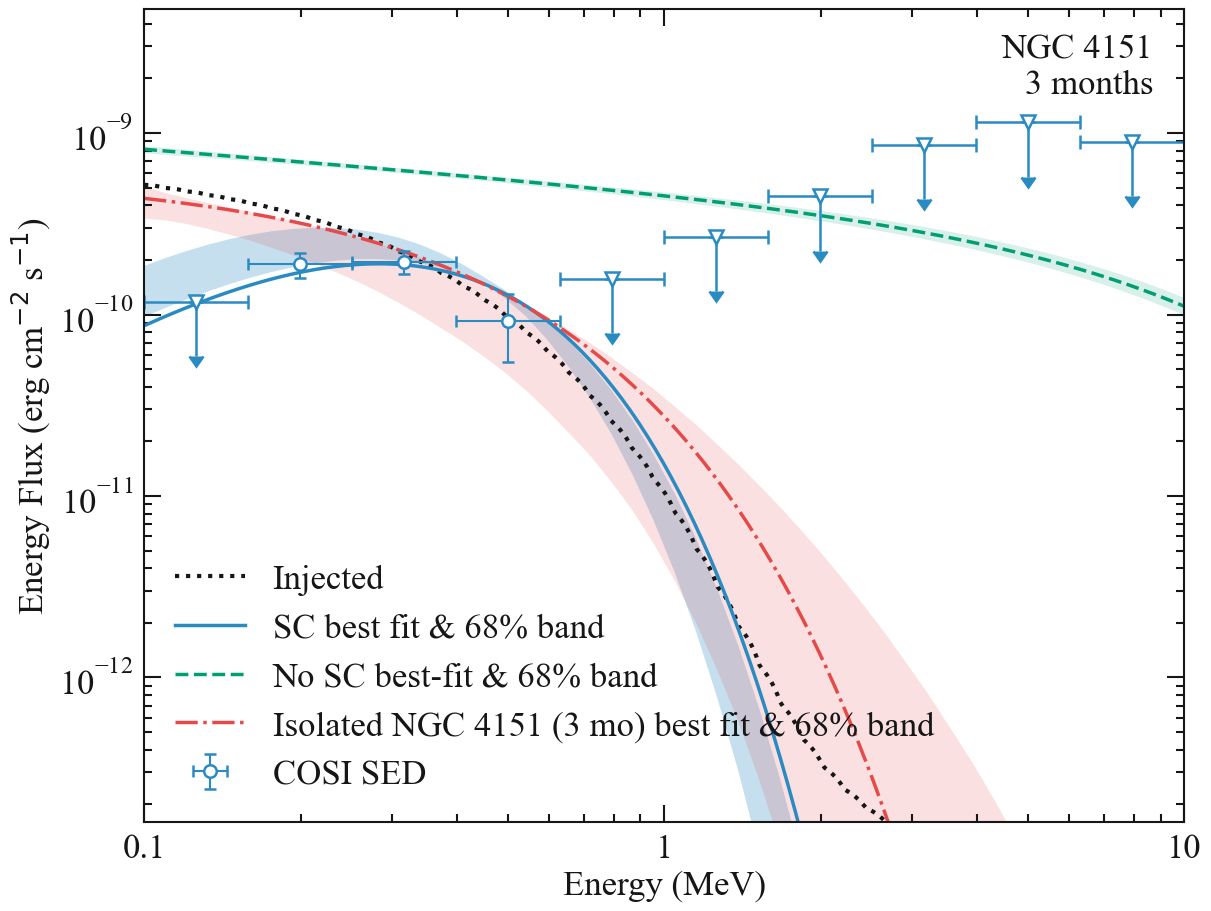

In [38]:
fit_outputs = {"parallel chunks": parallel_result}
parallel_figure = plot_method_sed(
    "parallel chunks", "NGC4151_DC4_paper_parallel_catalog", BLUE,
)


## Figure 1b: updated 0.30 mock, matched source-catalog settings

This reproduces the corresponding **parallel-chunks** catalog analysis from `NGC4151_DC4_Parallel_vs_FitNorm_SED_Plots.ipynb`, now with the **same CPL bounds, response, GTI, background, SED method, and white plotting style as Figure 1**. Only the full-mock data and the isolated NGC 4151 source file change. The modified source-only HDF5 is paired with the updated full mock; it is not added to the full mock a second time. The injected reference is the analytic 0.30 CPL + PL spectrum.

The three cells below are independent: prepare the two updated histograms, run the quick one-source comparison fits, then run or load the slower 71-source catalog plus independent SED fit. The response templates already built for Figure 1 are reused when their detector axes match. A small plot-data cache avoids repeating the expensive catalog and SED fit after the first successful run. If a scientific input changes, the cache is rejected. The original and updated catalog curves can then be compared under identical fit settings.


### Fast reference from the earlier notebook

The image below is the saved parallel-chunks plot from `NGC4151_DC4_Parallel_vs_FitNorm_SED_Plots.ipynb`. It displays immediately, without another fit. That older run allowed a different CPL index range and used its own SED-limit treatment, so use the **matched fit and plot cells below** for a controlled original-versus-updated comparison.


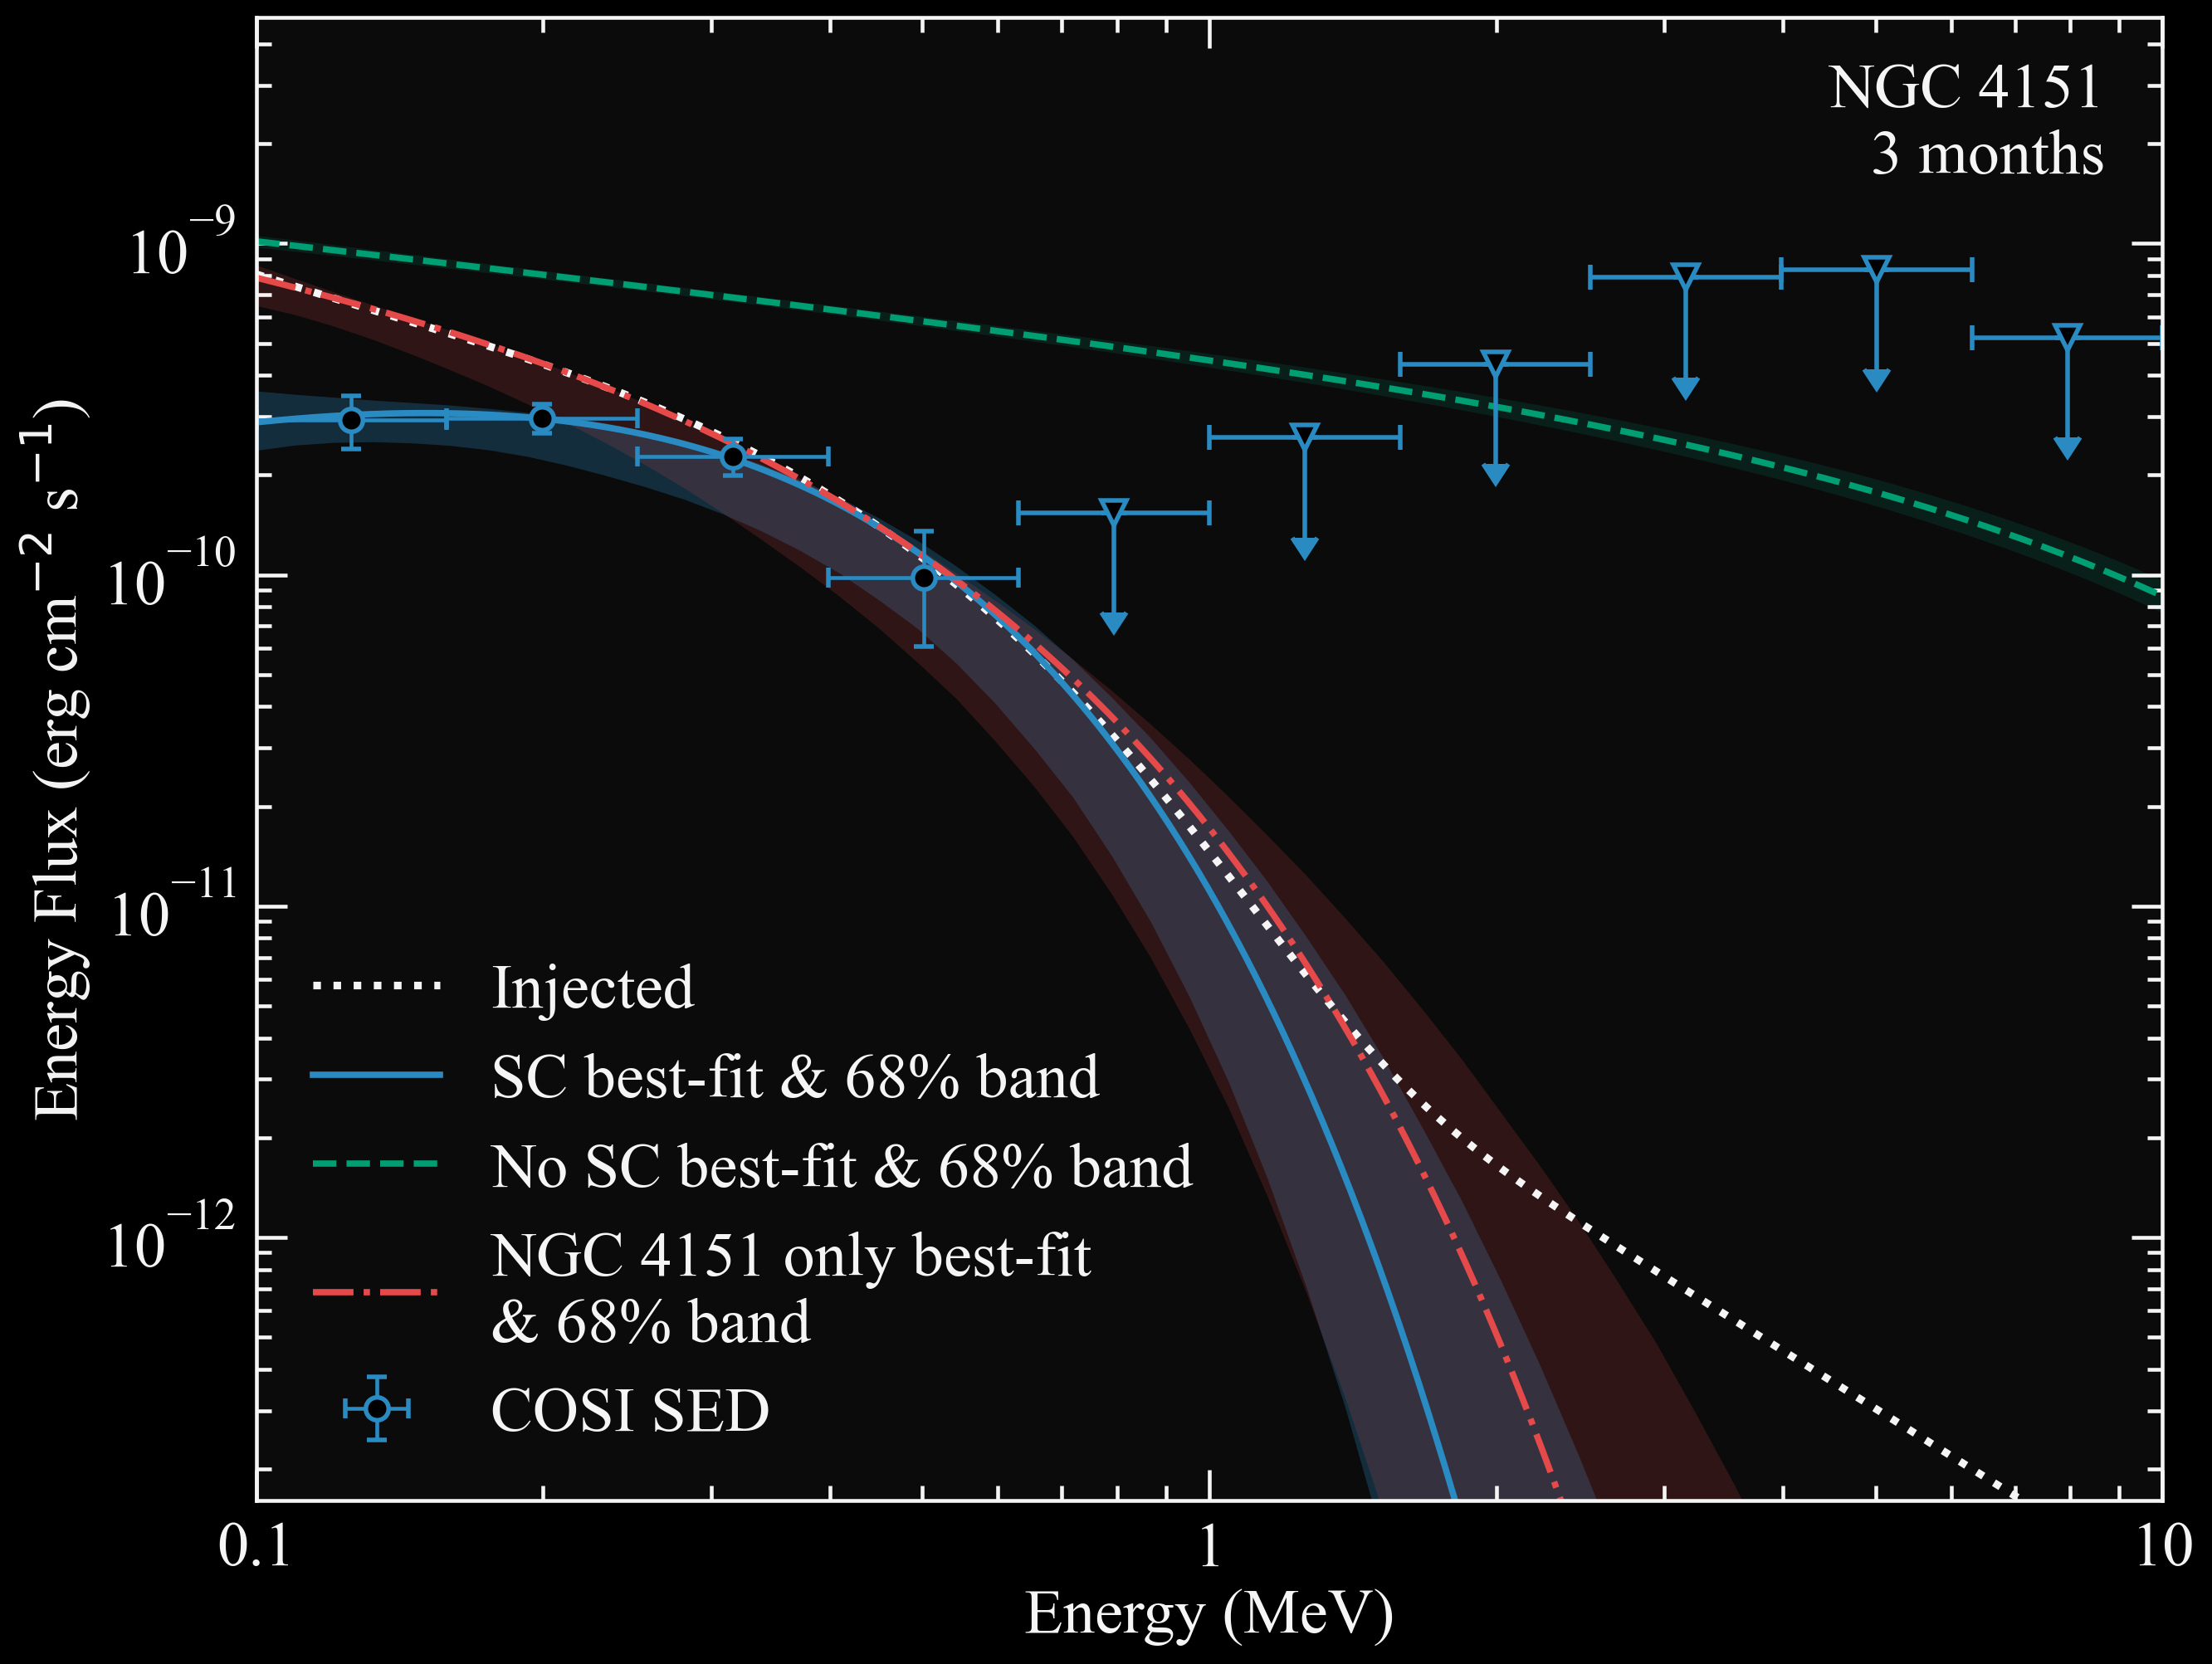

In [39]:
from IPython.display import Image as NotebookImage
archived_updated_plot = notebook_dir / "plots/NGC4151_parallel_chunks_sed_black.png"
if not archived_updated_plot.is_file():
    raise FileNotFoundError(archived_updated_plot)
display(NotebookImage(filename=str(archived_updated_plot)))


In [40]:
updated_data_hist = load_selected_histogram(
    updated_mock_data_path, source_gti, agn_config, already_selected=True,
)
if updated_data_hist.axes != data_hist.axes:
    raise ValueError("Updated full mock has different detector bins")
updated_data_hist *= exposure_multiplier
updated_data = EmCDSBinnedData(updated_data_hist)
# The modified 0.30 source and instrumental background were loaded in cell 10.
updated_isolated_data = EmCDSBinnedData(one_source_data_hist_three_month)
if updated_isolated_data.axes != comparison_data.axes:
    raise ValueError("Modified isolated source has different detector bins")
print("Original full mock counts:", float(_dense_counts(data_hist).sum()))
print("Updated full mock counts:", float(_dense_counts(updated_data_hist).sum()))
print("Changed full-mock counts:",
      float(_dense_counts(updated_data_hist).sum() - _dense_counts(data_hist).sum()))


Original full mock counts: 26164189.0
Updated full mock counts: 26185378.398761287
Changed full-mock counts: 21189.39876128733


In [41]:
# These quick fits use the same ordinary point response and background
# settings as Figure 1. Only their observed histograms change.
updated_full_mock_ngc_fit = fit_ngc_on_full_mock_cpl(
    observed_data=updated_data, source_file=updated_mock_data_path,
    cache_name="NGC4151_DC4_paper_updated_mock_no_catalog_comparison.json",
)
updated_one_source_fit = fit_one_source_cpl(
    observed_data=updated_isolated_data, source_file=ngc_only_source_path,
    cache_name="NGC4151_DC4_paper_modified_source_cpl_3months.json",
)
print("Updated-mock No SC fit:",
      {k: updated_full_mock_ngc_fit[k] for k in ("K", "index", "xc (keV)")})
print("Modified-source isolated fit:",
      {k: updated_one_source_fit[k] for k in ("K", "index", "xc (keV)")})


19:08:47 INFO      set the minimizer to minuit                                             ]8;id=29220;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py\joint_likelihood.py]8;;\:]8;id=427277;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py#1017\1017]8;;\

19:08:57 WARNING   50.260000000000005 percent of samples have been thrown away because     ]8;id=103154;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/analysis_results.py\analysis_results.py]8;;\:]8;id=712975;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/analysis_results.py#1645\1645]8;;\
                  they failed the constraints on the parameters. This results might not be                         
                  suitable for error propagation. Enlarge the boundaries until you loose                           
                  less than 1 percent of the samples.                                                              

19:08:57 WARNING   The current value of the parameter K (1.0) was above the new maximum 0.01.      ]8;id=298755;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=647242;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter xc (10.0) was below the new minimum 100.0.   ]8;id=179818;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=624900;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

         WARNING   The current value of the parameter K (1.0) was above the new maximum 0.01.      ]8;id=553680;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=826961;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

...

         WARNING   The current value of the parameter K (1.0) was above the new maximum 0.01.      ]8;id=833750;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=452780;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter xc (10.0) was below the new minimum 100.0.   ]8;id=131149;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=463887;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

         WARNING   The current value of the parameter K (1.0) was above the new maximum 0.01.      ]8;id=50329;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=458015;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter xc (10.0) was below the new minimum 100.0.   ]8;id=716355;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=284438;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

NGC-only + background CPL fit: {'K': 1.2418782540051991e-05, 'index': -2.430586079351245, 'xc (keV)': 328.5988853065579, 'background (Hz)': 25.571551337345372}
Saved fitted parameters: /Users/parshadkp/Software/cosipy/docs/tutorials/spectral_fits/continuum_fit/AGN/plots/NGC4151_DC4_paper_modified_source_cpl_3months.json
Updated-mock No SC fit: {'K': 1.2817906480224158e-05, 'index': -2.320360784311587, 'xc (keV)': 9999.999509412008}
Modified-source isolated fit: {'K': 1.2418782540051991e-05, 'index': -2.430586079351245, 'xc (keV)': 328.5988853065579}


### Matched updated-mock source-catalog fit and SED

These are the costly cells. It loads the fit and SED arrays from a validated local cache on later runs. Set `FORCE_REFIT_UPDATED = True` in the cell to recompute. The first run still evaluates the 71-source likelihood and ten independent SED bins, including Bayesian limits where TS < 1. The global fit and SED are separate cells, so a failed SED leaves the fitted catalog result in memory. For just the two catalog figures, stop after the updated-mock plot; the six-month and isolated 24-month cells below are optional.


In [42]:
# The large extended response is already open. Reuse the 71 source-specific
# temporal response templates from Figure 1; they depend on axes, pointing,
# light curves and catalog, not on the observed counts in the mock histogram.
# The first run still must fit the updated mock and ten independent SED bins.
UPDATED_PLOT_CACHE_VERSION = "updated-mock-matched-v1"
updated_plot_cache = notebook_dir / "plots" / "NGC4151_DC4_paper_updated_mock_SC_plot_cache.npz"
FORCE_REFIT_UPDATED = False


def _input_stamp(path, *, hash_contents=False):
    path = Path(path).resolve()
    info = path.stat()
    stamp = {"path": str(path), "bytes": info.st_size, "mtime_ns": info.st_mtime_ns}
    if hash_contents:
        stamp["sha256"] = hashlib.sha256(path.read_bytes()).hexdigest()
    return stamp


def updated_cache_identity():
    return {
        "version": UPDATED_PLOT_CACHE_VERSION,
        "mock": _input_stamp(updated_mock_data_path, hash_contents=True),
        "modified source": _input_stamp(ngc_only_source_path, hash_contents=True),
        "background": _input_stamp(background_path, hash_contents=True),
        "catalog": _input_stamp(parallel_catalog_path, hash_contents=True),
        "recipe": _input_stamp(parallel_recipe_path, hash_contents=True),
        "orientation": _input_stamp(orientation_path),
        "detector response": _input_stamp(response_path),
        "index bounds": [-5., -1e-3],
        "exposure multiplier": exposure_multiplier,
    }


def _optional_band(values):
    return np.array([], dtype=float) if values is None else np.asarray(values, dtype=float)


def save_updated_catalog_cache(result, identity):
    sed = result["sed"]
    meta = {
        "identity": identity,
        "K": result["K"], "index": result["index"],
        "xc (keV)": result["xc (keV)"],
        "background (Hz)": result["background (Hz)"],
        "log likelihood": result["log likelihood"],
        "parameter intervals 68": result["parameter intervals 68"],
        "catalog file": result["catalog file"],
        "catalog sha256": result["catalog sha256"],
        "CPL index lower bound": result["CPL index lower bound"],
        "CPL index upper bound": result["CPL index upper bound"],
        "spectral shape": sed["spectral shape"],
    }
    updated_plot_cache.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(
        updated_plot_cache, metadata=json.dumps(meta),
        fit_flux=np.asarray(result["fit flux"]),
        fit_energy=np.asarray(result["fit energy keV"]),
        fit_low=_optional_band(result["fit flux low 68"]),
        fit_high=_optional_band(result["fit flux high 68"]),
        sed_edges=np.asarray(sed["edges keV"]),
        sed_pivot=np.asarray(sed["pivot keV"]),
        sed_k=np.asarray(sed["K"]), sed_ts=np.asarray(sed["TS"]),
        sed_low68=np.asarray(sed["lower 68"]),
        sed_high68=np.asarray(sed["upper 68"]),
        sed_high95=np.asarray(sed["upper 95"]),
    )
    print("Saved updated catalog fit + SED plot cache:", updated_plot_cache)


def load_updated_catalog_cache(identity):
    if not updated_plot_cache.is_file():
        return None
    with np.load(updated_plot_cache, allow_pickle=False) as cache:
        meta = json.loads(str(cache["metadata"].item()))
        if meta.get("identity") != identity:
            print("Updated catalog cache is stale; refitting with the current inputs.")
            return None
        low = np.asarray(cache["fit_low"]).copy()
        high = np.asarray(cache["fit_high"]).copy()
        result = {
            "K": float(meta["K"]), "index": float(meta["index"]),
            "xc (keV)": float(meta["xc (keV)"]),
            "background (Hz)": float(meta["background (Hz)"]),
            "log likelihood": float(meta["log likelihood"]),
            "parameter intervals 68": meta["parameter intervals 68"],
            "catalog file": meta["catalog file"],
            "catalog sha256": meta["catalog sha256"],
            "CPL index lower bound": meta["CPL index lower bound"],
            "CPL index upper bound": meta["CPL index upper bound"],
            "fit flux": np.asarray(cache["fit_flux"]).copy(),
            "fit energy keV": np.asarray(cache["fit_energy"]).copy(),
            "fit flux low 68": low if low.size else None,
            "fit flux high 68": high if high.size else None,
            "sed": {
                "edges keV": np.asarray(cache["sed_edges"]).copy(),
                "pivot keV": np.asarray(cache["sed_pivot"]).copy(),
                "K": np.asarray(cache["sed_k"]).copy(),
                "TS": np.asarray(cache["sed_ts"]).copy(),
                "lower 68": np.asarray(cache["sed_low68"]).copy(),
                "upper 68": np.asarray(cache["sed_high68"]).copy(),
                "upper 95": np.asarray(cache["sed_high95"]).copy(),
                "spectral shape": meta["spectral shape"],
            },
        }
    print("Loaded updated catalog fit + SED from", updated_plot_cache)
    return result



In [43]:
updated_identity = updated_cache_identity()
prior_updated_result = globals().get("updated_catalog_result")
updated_catalog_result = None if FORCE_REFIT_UPDATED else load_updated_catalog_cache(updated_identity)
if updated_catalog_result is None:
    if (not FORCE_REFIT_UPDATED and prior_updated_result is not None
            and prior_updated_result.get("updated cache identity") == updated_identity
            and "model for sed" in prior_updated_result):
        updated_catalog_result = prior_updated_result
        print("Reusing updated global SC fit already in this kernel")
    else:
        response_templates = parallel_result.get("point responses for sed")
        if response_templates is None:
            raise RuntimeError("Run the original three-month catalog fit before the updated fit")
        updated_catalog_result = fit_parallel_catalog(
            observed_data=updated_data,
            point_responses_override=response_templates,
        )
        updated_catalog_result["updated cache identity"] = updated_identity
print("Updated-mock SC fit:",
      {k: updated_catalog_result[k] for k in ("K", "index", "xc (keV)", "background (Hz)")})


Loaded updated catalog fit + SED from /Users/parshadkp/Software/cosipy/docs/tutorials/spectral_fits/continuum_fit/AGN/plots/NGC4151_DC4_paper_updated_mock_SC_plot_cache.npz
Updated-mock SC fit: {'K': 1.637906144483947e-05, 'index': -1.0133260145529133, 'xc (keV)': 158.70434036139994, 'background (Hz)': 25.527763928030467}


In [44]:
# This cell leaves updated_catalog_result intact if SED optimization fails.
# Rerun only this cell after fixing an SED issue; the 71-source global fit
# remains available in the current kernel.
if "sed" not in updated_catalog_result:
    updated_catalog_result["sed"] = extract_binned_sed(
        updated_catalog_result["model for sed"],
        updated_catalog_result["shape for sed"],
        updated_catalog_result["point responses for sed"],
        updated_catalog_result["background for sed"],
        observed_hist=updated_data_hist, data_object=updated_data,
        ordinary_psr=psr, extended_psr=esr, label="updated 0.30 full mock",
    )
    save_updated_catalog_cache(updated_catalog_result, updated_identity)
else:
    print("Updated-mock SC SED loaded from the validated cache")
print("Updated-mock SED bins:", len(updated_catalog_result["sed"]["K"]))


Updated-mock SC SED loaded from the validated cache
Updated-mock SED bins: 10


### Updated-mock catalog plot

The blue SC and green No SC curves use the updated full mock. The red isolated curve uses only the modified 0.30 NGC 4151 source plus instrumental background. Compare this plot with Figure 1, whose full mock and isolated source both come from the original DC4 injection.


Saved /Users/parshadkp/Library/CloudStorage/OneDrive-ClemsonUniversity/Papers/DC4_Paper/NGC4151_DC4_paper_updated_mock_SC_white.pdf and /Users/parshadkp/Library/CloudStorage/OneDrive-ClemsonUniversity/Papers/DC4_Paper/NGC4151_DC4_paper_updated_mock_SC_white.png


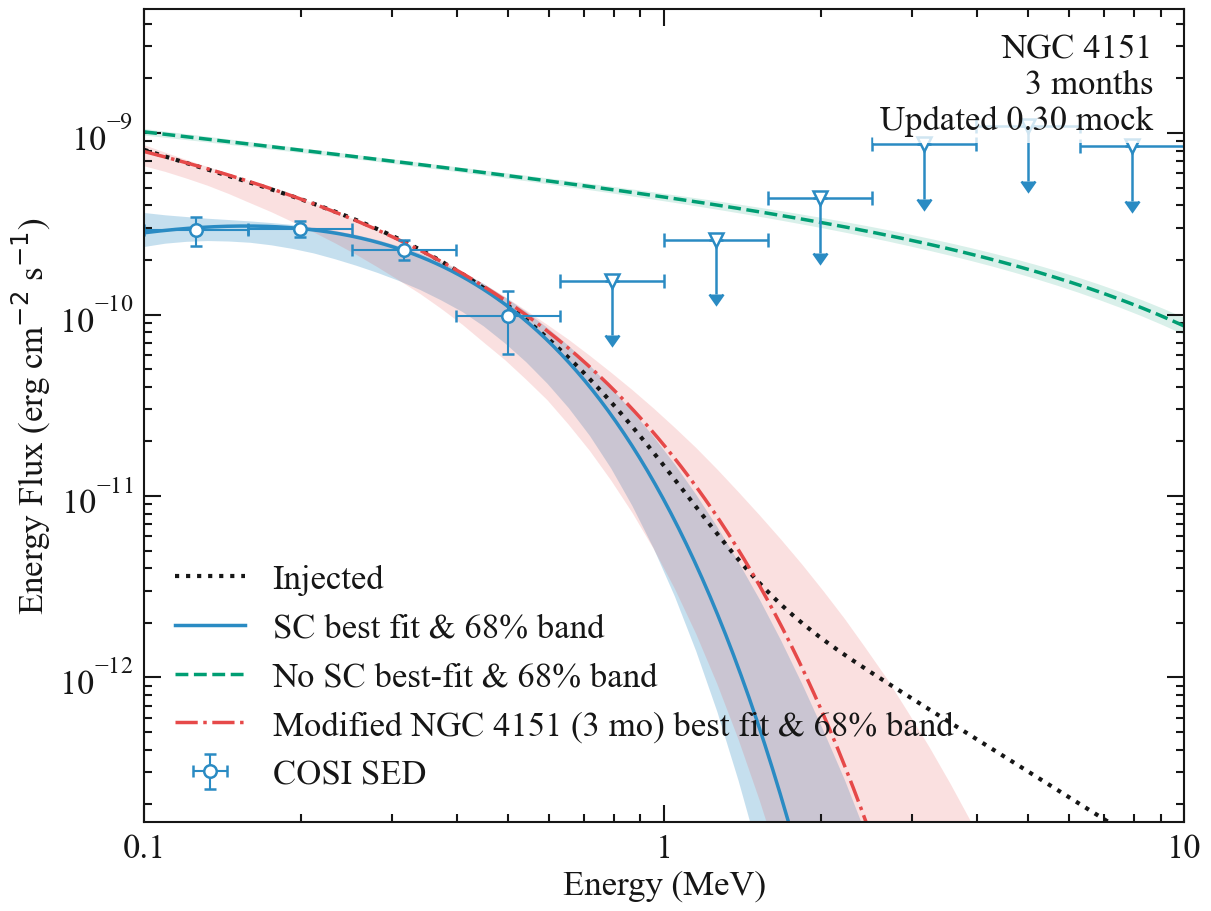

,data,counts,K,index,xc (keV)
0,Original DC4 mock,2.616419e+07,0.000011,-0.001003,141.388141
1,Updated 0.30 mock,2.618538e+07,0.000016,-1.013326,158.704340


Both SC fits used source_catalog_DC4_all_71files_NGC4151_GTI_elapsed_lightcurve_response_norm.yaml with the same 3-month GTI, response, background, and CPL bounds.


In [45]:
def updated_injected_flux(energies_keV):
    return np.asarray([spectrum_inj_isolated.evaluate_at(e) for e in energies_keV], dtype=float)

updated_plot_context = {
    "catalog fit": updated_catalog_result,
    "mock path": updated_mock_data_path,
    "full mock comparison": updated_full_mock_ngc_fit,
    "isolated comparison": updated_one_source_fit,
    "isolated source path": ngc_only_source_path,
    "injected flux": updated_injected_flux,
    "isolated label": "Modified NGC 4151 (3 mo) best fit & 68% band",
    "annotation": "NGC 4151\n3 months\nUpdated 0.30 mock",
}
updated_parallel_figure = plot_method_sed(
    "parallel chunks", "NGC4151_DC4_paper_updated_mock_SC", BLUE,
    context=updated_plot_context,
)
comparison = pd.DataFrame([
    {"data": "Original DC4 mock", "counts": float(_dense_counts(data_hist).sum()),
     **{k: parallel_result[k] for k in ("K", "index", "xc (keV)")}},
    {"data": "Updated 0.30 mock", "counts": float(_dense_counts(updated_data_hist).sum()),
     **{k: updated_catalog_result[k] for k in ("K", "index", "xc (keV)")}},
])
display(comparison)
print("Both SC fits used", parallel_catalog_path.name,
      "with the same 3-month GTI, response, background, and CPL bounds.")


### Check against the earlier updated-mock catalog fit

The earlier `NGC4151_DC4_Parallel_vs_FitNorm_SED_Plots.ipynb` uses the same updated mock, catalog, recipe, GTI, and detector/background responses. It allows CPL `index` from −10 to +10; this notebook uses −5 to −0.001. Both best fits lie inside both ranges. Compare the stored global-fit values below without repeating the SED or 71-source fit. A small likelihood difference reflects the nearly degenerate CPL shape and different optimizer parameter bounds.


In [46]:
# This comparison reads the completed global fit from the earlier notebook.
# It never launches another source-catalog fit or SED extraction.
older_fit_file = notebook_dir / "plots" / "NGC4151_parallel_chunks_global_fit.json"
older_catalog_fit = json.loads(older_fit_file.read_text())
if older_catalog_fit["catalog sha256"] != updated_catalog_result["catalog sha256"]:
    raise ValueError("The earlier fit used a different source catalog")
if not np.isclose(older_catalog_fit["log likelihood"],
                  118228904.53237784, rtol=0., atol=1e-4):
    print("The earlier stored fit has changed; verify its mock-data selection.")
comparison_rows = []
for label, fit in (("Earlier updated-mock notebook", older_catalog_fit),
                   ("This paper notebook", updated_catalog_result)):
    comparison_rows.append({
        "Fit": label,
        "K (ph cm⁻² s⁻¹ keV⁻¹)": fit["K"],
        "index": fit["index"],
        "cutoff (keV)": fit["xc (keV)"],
        "background (Hz)": fit["background (Hz)"],
        "log likelihood": fit["log likelihood"],
    })
display(pd.DataFrame(comparison_rows))
delta_2logl = 2 * (older_catalog_fit["log likelihood"]
                   - updated_catalog_result["log likelihood"])
print(f"2 × (earlier log L − paper log L) = {delta_2logl:.4f}")
print("Both solutions are interior to both index ranges; "
      "the tiny likelihood difference is an optimizer/bounds effect, "
      "not a different source catalog or updated-mock histogram.")


,Fit,K (ph cm⁻² s⁻¹ keV⁻¹),index,cutoff (keV),background (Hz),log likelihood
0,Earlier updated-mock notebook,0.000015,-1.115742,170.094399,25.527477,1.182289e+08
1,This paper notebook,0.000016,-1.013326,158.704340,25.527764,1.182289e+08


2 × (earlier log L − paper log L) = 0.0179
Both solutions are interior to both index ranges; the tiny likelihood difference is an optimizer/bounds effect, not a different source catalog or updated-mock histogram.


## Six-month exposure scenario: 2× the selected three-month data

This cell repeats the **same** three-month attitude, GTI, source light curves, and binned counts at twice the livetime. It doubles the full-mock counts, instrumental-background counts, point responses, and extended response while leaving all source fluxes unchanged. It fits the 71-source SC model and its independent SED, then saves a white-background figure. This is an exposure-scaling forecast, not a separate six-month simulation or a new light-curve time range. The original three-month objects are restored even if the six-month fit fails.

Because both observed and predicted counts are multiplied by two, an exact optimization has the **same best-fit spectral parameters** as the three-month fit; statistical intervals narrow and likelihood-ratio TS values approximately double. A changed best-fit shape would point to optimization or implementation differences, not new information in this repeated histogram.


19:09:58 INFO      set the minimizer to minuit                                             ]8;id=165949;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py\joint_likelihood.py]8;;\:]8;id=730555;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py#1017\1017]8;;\

19:10:01 WARNING   The current value of the parameter K (1.0) was above the new maximum 0.01.      ]8;id=263478;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=260730;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter xc (10.0) was below the new minimum 100.0.   ]8;id=867069;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=105353;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

19:10:08 WARNING   The current value of the parameter K (1.0) was above the new maximum 0.01.      ]8;id=777348;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=133305;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter xc (10.0) was below the new minimum 100.0.   ]8;id=190703;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=737649;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

...

  0%|          | 0/1800 [00:00<?, ?it/s]

19:24:10 INFO      Mean acceptance fraction: 0.7612777777777777                                ]8;id=547839;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/bayesian/emcee_sampler.py\emcee_sampler.py]8;;\:]8;id=721078;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/bayesian/emcee_sampler.py#145\145]8;;\

19:24:11 INFO      fit restored to maximum of posterior                                         ]8;id=36451;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/bayesian/sampler_base.py\sampler_base.py]8;;\:]8;id=651361;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/bayesian/sampler_base.py#168\168]8;;\

         INFO      fit restored to maximum of posterior                                         ]8;id=154534;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/bayesian/sampler_base.py\sampler_base.py]8;;\:]8;id=642799;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/bayesian/sampler_base.py#168\168]8;;\

six-month SC exposure SED bin 10: TS=0.00, Bayesian 95% K UL=4.939e-09
SED: 3 bins at TS >= 4 of 10 Ei bins
Six-month live time: 1,960,830.0 s (3-month: 980,415.0 s)
Six-month mock counts: 52,328,378
Six-month SC log L: 272477989.561842
Three- vs six-month SC best-fit values:
  K: 3 months=1.09801e-05; 6 months=1.0977e-05
  index: 3 months=-0.00100314; 6 months=-0.00102566
  xc (keV): 3 months=141.388; 6 months=141.416
  background (Hz): 3 months=25.523; 6 months=25.523
  K: 1.098e-05 (−1.333e-06/+4.167e-06)
  index: -0.00103 (−0.00374/+2.57e-05)
  xc (keV): 141.4 (−20.93/+6.743)
  background (Hz): 25.523 (−0.0053238/+0.0044054)
Saved /Users/parshadkp/Library/CloudStorage/OneDrive-ClemsonUniversity/Papers/DC4_Paper/NGC4151_DC4_paper_SC_6months_white.pdf and /Users/parshadkp/Library/CloudStorage/OneDrive-ClemsonUniversity/Papers/DC4_Paper/NGC4151_DC4_paper_SC_6months_white.png


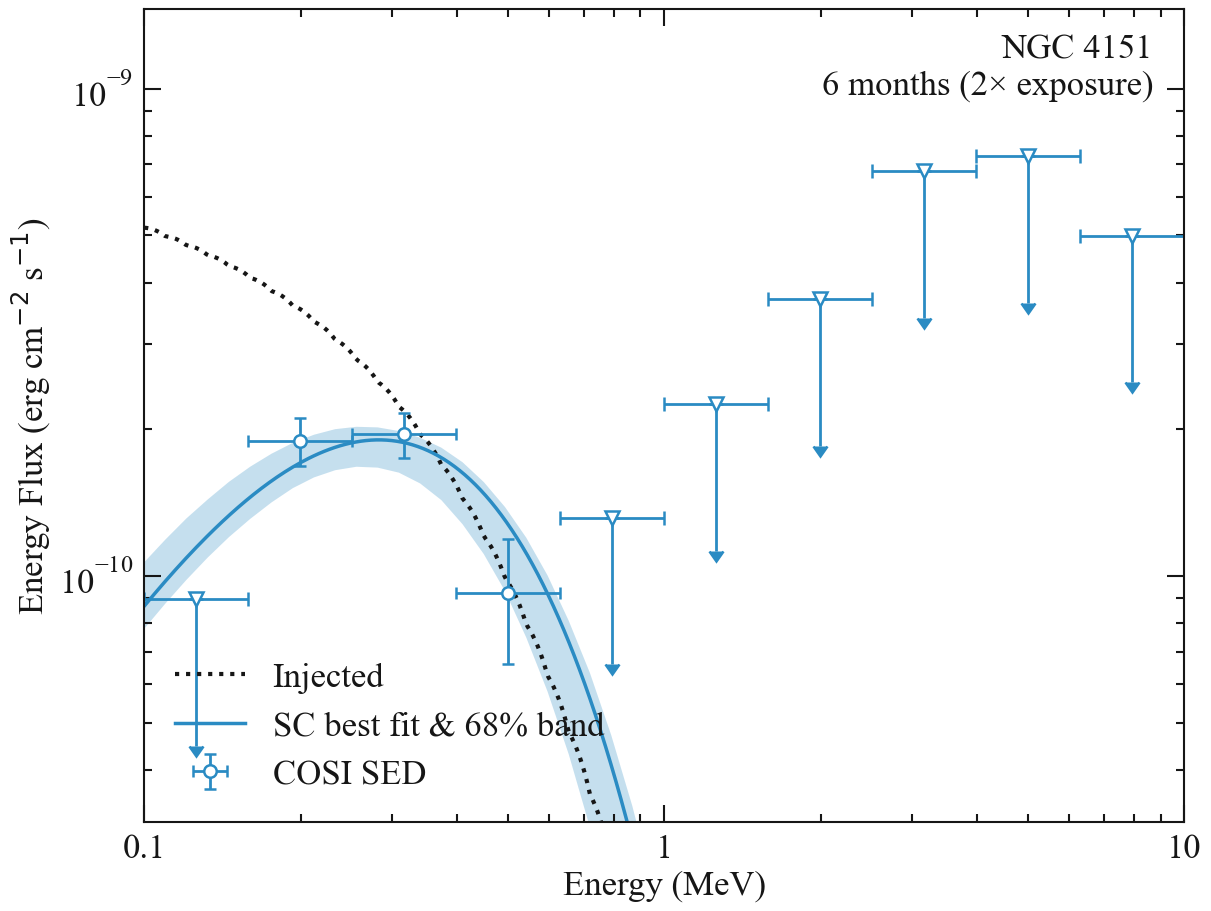

In [47]:
# Keep this as one cell so the doubled response cannot leak into later fits.
if exposure_multiplier != 1:
    raise ValueError("The six-month forecast expects the base notebook to be at 3 months")
if data_hist.axes != total_bkg.axes:
    raise ValueError("Data and background detector axes differ")

sixmonth_data_hist = deepcopy(data_hist)
sixmonth_data_hist *= 2.0
sixmonth_bkg_hist = deepcopy(total_bkg)
sixmonth_bkg_hist *= 2.0
sixmonth_history = SpacecraftHistory(
    sc_orientation_cut.obstime, sc_orientation_cut.attitude,
    sc_orientation_cut.location, livetime=2.0 * sc_orientation_cut.livetime,
)
sixmonth_history.cache_earth_occ = sc_orientation_cut.cache_earth_occ
sixmonth_livetime = sixmonth_history.cumulative_livetime().to_value(u.s)
assert np.isclose(sixmonth_livetime, 2.0 * scaled_livetime)
assert np.isclose(_dense_counts(sixmonth_data_hist).sum(),
                  2.0 * _dense_counts(data_hist).sum())
sixmonth_data = EmCDSBinnedData(sixmonth_data_hist)
sixmonth_instrument_response = BinnedInstrumentResponse(dr, sixmonth_data)
sixmonth_psr = BinnedThreeMLPointSourceResponse(
    data=sixmonth_data, instrument_response=sixmonth_instrument_response,
    sc_history=sixmonth_history, energy_axis=dr.axes["Ei"],
    polarization_axis=dr.axes["Pol"] if "Pol" in dr.axes.labels else None,
    nside=2 * sixmonth_data.axes["PsiChi"].nside,
)
sixmonth_background_rate = float(_dense_counts(sixmonth_bkg_hist).sum()) / sixmonth_livetime
assert np.isclose(sixmonth_background_rate, background_rate_initial)

# The NSIDE-8 extended response is about 13 GiB. Scale it in place rather
# than making a second copy, and restore it in the finally block.
_three_month_context = {name: globals()[name] for name in (
    "data_hist", "total_bkg", "data", "instrument_response", "psr", "esr",
    "sc_orientation", "scaled_livetime", "background_rate_initial",
    "exposure_multiplier",
)}
try:
    extended_response *= 2.0
    sixmonth_esr = BinnedThreeMLExtendedSourceResponse(
        data=sixmonth_data, precomputed_psr=extended_response,
    )
    globals().update({
        "data_hist": sixmonth_data_hist,
        "total_bkg": sixmonth_bkg_hist,
        "data": sixmonth_data,
        "instrument_response": sixmonth_instrument_response,
        "psr": sixmonth_psr,
        "esr": sixmonth_esr,
        "sc_orientation": sixmonth_history,
        "scaled_livetime": sixmonth_livetime,
        "background_rate_initial": sixmonth_background_rate,
        "exposure_multiplier": 2,
    })
    refresh_dc4_response_integrators()
    sixmonth_result = fit_parallel_catalog()
    sixmonth_result["sed"] = extract_binned_sed(
        sixmonth_result["model for sed"], sixmonth_result["shape for sed"],
        sixmonth_result["point responses for sed"],
        sixmonth_result["background for sed"],
        observed_hist=sixmonth_data_hist, data_object=sixmonth_data,
        ordinary_psr=sixmonth_psr, extended_psr=sixmonth_esr,
        label="six-month SC exposure",
    )
finally:
    globals().update(_three_month_context)
    extended_response /= 2.0

print(f"Six-month live time: {sixmonth_livetime:,.1f} s "
      f"(3-month: {scaled_livetime:,.1f} s)")
print(f"Six-month mock counts: {_dense_counts(sixmonth_data_hist).sum():,.0f}")
print(f"Six-month SC log L: {sixmonth_result['log likelihood']:.6f}")
print("Three- vs six-month SC best-fit values:")
for name in ("K", "index", "xc (keV)", "background (Hz)"):
    print(f"  {name}: 3 months={parallel_result[name]:.6g}; "
          f"6 months={sixmonth_result[name]:.6g}")
for name, spec in (("K", ".4g"), ("index", ".3g"),
                   ("xc (keV)", ".4g"), ("background (Hz)", ".5g")):
    print(f"  {name}: {format_parameter_68(sixmonth_result, name, spec)}")

# The fit and SED arrays are now independent of the temporary scaled response.
# Release the large model/response references before drawing the paper figure.
for key in ("model for sed", "shape for sed", "point responses for sed",
            "background for sed"):
    sixmonth_result.pop(key, None)
gc.collect()

sed = sixmonth_result["sed"]
pivot = np.asarray(sed["pivot keV"], dtype=float)
edges = np.asarray(sed["edges keV"], dtype=float)
detected = ((sed["TS"] >= 4.) & (sed["K"] > 0.) &
            (sed["lower 68"] > 0.) & np.isfinite(sed["upper 68"]))
upper = (~detected) & np.isfinite(sed["upper 95"]) & (sed["upper 95"] > 0.)
plot_energy = PLOT_ENERGY_KEV
x = plot_energy / 1000.
pivot_keV = parallel_model.ngc4151.spectrum.main.composite.piv_1.value
with paper_style("light", FONT_SIZE):
    sixmonth_figure, ax = plt.subplots(figsize=(12, 9), constrained_layout=True)
    style_axis(ax, "light", FONT_SIZE)
    ax.plot(x, KEV_TO_ERG * plot_energy**2 * original_injected_flux(plot_energy),
            color=ink("light"), ls=":", lw=3, label="Injected")
    ax.plot(x, KEV_TO_ERG * plot_energy**2 * fitted_cpl_flux(
        sixmonth_result, plot_energy, pivot_keV), color=BLUE, lw=2.5,
        label="SC best fit & 68% band" if sixmonth_result["fit flux low 68"] is not None
        else "SC best fit")
    if sixmonth_result["fit flux low 68"] is not None:
        fit_e = np.asarray(sixmonth_result["fit energy keV"], dtype=float)
        low = np.where(sixmonth_result["fit flux low 68"] > 0,
                       sixmonth_result["fit flux low 68"], np.nan)
        high = np.where(sixmonth_result["fit flux high 68"] > 0,
                        sixmonth_result["fit flux high 68"], np.nan)
        ax.fill_between(fit_e/1000., KEV_TO_ERG*fit_e**2*low,
                        KEV_TO_ERG*fit_e**2*high, color=BLUE, alpha=0.27,
                        linewidth=0)
    if np.any(detected):
        p = pivot[detected]
        k = sed["K"][detected]
        ax.errorbar(p/1000., KEV_TO_ERG*p**2*k,
                    xerr=np.vstack((p-edges[:-1][detected],
                                    edges[1:][detected]-p))/1000.,
                    yerr=np.vstack((KEV_TO_ERG*p**2*(k-sed["lower 68"][detected]),
                                    KEV_TO_ERG*p**2*(sed["upper 68"][detected]-k))),
                    fmt="o", color=BLUE, ecolor=BLUE, markerfacecolor="white",
                    markeredgewidth=1.8, markersize=9, capsize=4,
                    label="COSI SED")
    if np.any(upper):
        p = pivot[upper]
        limits = KEV_TO_ERG*p**2*sed["upper 95"][upper]
        ax.errorbar(p/1000., limits,
                    xerr=np.vstack((p-edges[:-1][upper],
                                    edges[1:][upper]-p))/1000.,
                    yerr=np.maximum(0.5*limits, np.finfo(float).tiny),
                    uplims=True, fmt="v", color=BLUE, ecolor=BLUE,
                    markerfacecolor="white", markeredgewidth=1.8,
                    markersize=10, capsize=5)
    visible = np.r_[KEV_TO_ERG*pivot[upper]**2*sed["upper 95"][upper],
                    KEV_TO_ERG*pivot[detected]**2*sed["K"][detected]]
    ax.set(xscale="log", yscale="log", xlim=(0.1, 10.),
           ylim=(max(1e-14, 0.35*np.min(visible)) if visible.size else 1e-14,
                 max(1e-9, 2*np.max(visible)) if visible.size else 1e-9),
           xlabel="Energy (MeV)",
           ylabel=r"Energy Flux (erg cm$^{-2}$ s$^{-1}$)")
    ax.xaxis.set_major_locator(mticker.FixedLocator([0.1, 1., 10.]))
    ax.xaxis.set_major_formatter(mticker.FixedFormatter(["0.1", "1", "10"]))
    ax.text(0.97, 0.97, "NGC 4151\n6 months (2× exposure)",
            transform=ax.transAxes, ha="right", va="top", fontsize=FONT_SIZE,
            color=ink("light"),
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.78, pad=5))
    ax.legend(loc="lower left", frameon=False, fontsize=FONT_SIZE)
    PAPER_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    pdf_path = PAPER_OUTPUT_DIR / "NGC4151_DC4_paper_SC_6months_white.pdf"
    png_path = PAPER_OUTPUT_DIR / "NGC4151_DC4_paper_SC_6months_white.png"
    sixmonth_figure.savefig(pdf_path, format="pdf", facecolor="white",
                            edgecolor="white", transparent=False,
                            bbox_inches="tight")
    sixmonth_figure.savefig(png_path, dpi=220, facecolor="white",
                            edgecolor="white", transparent=False,
                            bbox_inches="tight")
    print("Saved", pdf_path, "and", png_path)
    plt.show()


## Isolated NGC 4151 CPL + PL fit

Use only `NGC_4151_ec200_0p30_DC4_COSI_cpl_pl_time_cut_in_fov.hdf5` plus the selected instrumental background. Repeat their selected three-month histograms and the GTI livetime eight times for a 24-month forecast. This leaves the SC fit at three months. The CPL index is fixed at its injected −1.75. Free parameters are CPL K and cutoff, PL K and index, and background rate. The two spectral components are fit jointly from six independent starts; the largest Poisson likelihood (and thus largest ΔTS against the common CPL null) is retained.


In [48]:
# Forecast eight repeats of the selected three-month isolated observation.
# This is only for the second figure and CPL+PL tail test. Figure 1 stays at three months.
isolated_exposure_multiplier = 8
isolated_exposure_months = 3 * isolated_exposure_multiplier
one_source_data_hist = deepcopy(one_source_data_hist_three_month)
one_source_data_hist *= isolated_exposure_multiplier
isolated_bkg_hist = deepcopy(total_bkg)
isolated_bkg_hist *= isolated_exposure_multiplier
isolated_sc_orientation = SpacecraftHistory(
    sc_orientation_cut.obstime, sc_orientation_cut.attitude,
    sc_orientation_cut.location,
    livetime=isolated_exposure_multiplier * sc_orientation_cut.livetime,
)
isolated_sc_orientation.cache_earth_occ = sc_orientation_cut.cache_earth_occ
isolated_livetime = isolated_sc_orientation.cumulative_livetime().to_value(u.s)
isolated_background_rate_initial = (
    float(isolated_bkg_hist.to_dense(copy=False).contents.sum()) / isolated_livetime
)
assert np.isclose(isolated_livetime, isolated_exposure_multiplier * fov_livetime)
assert np.isclose(isolated_background_rate_initial, background_rate_initial)
print(f"Isolated forecast: {isolated_exposure_months} months, "
      f"{isolated_livetime:,.1f} s livetime, "
      f"{float(one_source_data_hist.to_dense(copy=False).contents.sum()):,.1f} counts")
one_source_data = EmCDSBinnedData(one_source_data_hist)
one_source_instrument_response = BinnedInstrumentResponse(dr, one_source_data)
one_source_psr = BinnedThreeMLPointSourceResponse(
    data=one_source_data, instrument_response=one_source_instrument_response,
    sc_history=isolated_sc_orientation, energy_axis=dr.axes["Ei"],
    polarization_axis=dr.axes["Pol"] if "Pol" in dr.axes.labels else None,
    nside=2 * one_source_data.axes["PsiChi"].nside,
)


Isolated forecast: 24 months, 7,843,320.0 s livetime, 201,177,099.2 counts


In [49]:
def fit_isolated_cpl_pl_once(start, label):
    source = parallel_model.ngc4151
    cpl = Cutoff_powerlaw(K=start["K CPL"],
                          piv=200., index=-1.75, xc=start["xc (keV)"])
    tail = Powerlaw(K=start["K PL"], piv=200., index=start["index PL"])
    point = PointSource("ngc4151", l=source.position.l.value,
                        b=source.position.b.value, spectral_shape=cpl + tail)
    model = Model(point)
    shape = model.ngc4151.spectrum.main.composite
    for par in point.parameters.values():
        par.fix = True
    shape.K_1.min_value, shape.K_1.max_value = 1e-8, 1e-2
    shape.K_1.delta, shape.K_1.fix = 0.1*shape.K_1.value, False
    shape.index_1.value, shape.index_1.fix = -1.75, True
    shape.xc_1.min_value, shape.xc_1.max_value = 20., 10000.
    shape.xc_1.delta, shape.xc_1.fix = 20., False
    shape.K_2.min_value, shape.K_2.max_value = 1e-10, 1e-2
    shape.K_2.delta, shape.K_2.fix = 0.1*shape.K_2.value, False
    shape.index_2.min_value, shape.index_2.max_value = -10., -0.5
    shape.index_2.delta, shape.index_2.fix = 0.1, False
    expected = {shape.K_1.path, shape.xc_1.path, shape.K_2.path, shape.index_2.path}
    if set(model.free_parameters) != expected:
        raise RuntimeError("Expected free CPL K/xc and PL K/index only")
    background = FreeNormBinnedBackground(
        {"total_bkg": isolated_bkg_hist}, sc_history=isolated_sc_orientation, copy=True)
    folding = BinnedThreeMLModelFolding(data=one_source_data,
                                         point_source_response=one_source_psr)
    likelihood = PoissonLikelihood(one_source_data, folding, background)
    plugin = ThreeMLPluginInterface(f"cosi_isolated_cpl_pl_{label}", likelihood, folding, background)
    plugin.bkg_parameter["total_bkg"] = Parameter(
        "total_bkg", isolated_background_rate_initial, min_value=0., max_value=50.,
        delta=max(0.05*isolated_background_rate_initial, 1e-6), unit=u.Hz)
    joint = JointLikelihood(model, DataList(plugin), verbose=False)
    initial_log_likelihood = float(plugin.get_log_like())
    covariance_valid = fit_joint_with_fallback(joint, f"isolated CPL+PL ({label})")
    log_likelihood = float(plugin.get_log_like())
    if not np.isfinite(log_likelihood) or log_likelihood < initial_log_likelihood - 1e-3:
        raise RuntimeError(f"{label}: invalid or worsened Poisson optimum")
    fitted = joint.results.optimized_model.ngc4151.spectrum.main.composite
    return {
        "model": model, "background": background, "results": joint.results,
        "fitted": fitted, "covariance valid": covariance_valid,
        "log likelihood": log_likelihood,
        "start log likelihood": initial_log_likelihood,
        "background (Hz)": float(plugin.bkg_parameter["total_bkg"].value),
        "background parameter": plugin.bkg_parameter["total_bkg"],
        "label": label, "start": start,
    }


def fit_isolated_cpl_pl():
    """Run independent initializations and retain the largest Poisson likelihood.

    The CPL-only null uses the same data and is fit later. Since the null log L
    is common to every trial, largest alternative log L means largest Delta TS.
    """
    injected_k_cpl = float(parallel_model.ngc4151.spectrum.main.composite.K_1.value)
    injected_k_pl = float(spectrum_inj_tail.K.value)
    starts = [
        ("catalog",      1.0, 200., 1.0, -3.8),
        ("weak_tail",    1.2, 150., 0.2, -2.5),
        ("strong_tail",  0.8, 300., 3.0, -4.5),
        ("hard_tail",    1.0, 500., 1.0, -2.0),
        ("soft_tail",    1.0, 120., 2.0, -5.5),
        ("broad_cutoff", 1.5, 800., 0.1, -1.5),
    ]
    best = None
    history = []
    for label, cpl_scale, cutoff, pl_scale, pl_index in starts:
        start = {"K CPL": injected_k_cpl*cpl_scale, "xc (keV)": cutoff,
                 "K PL": injected_k_pl*pl_scale, "index PL": pl_index}
        try:
            trial = fit_isolated_cpl_pl_once(start, label)
        except (FitFailed, CannotComputeCovariance, BadCovariance,
                RuntimeError, ValueError) as exc:
            history.append({"start": label, **start, "status": type(exc).__name__,
                            "message": str(exc)})
            print(f"{label}: failed ({type(exc).__name__}: {exc})")
            gc.collect()
            continue
        fitted = trial["fitted"]
        record = {
            "start": label, **start, "status": "converged",
            "initial log likelihood": trial["start log likelihood"],
            "log likelihood": trial["log likelihood"],
            "fitted K CPL": float(fitted.K_1.value),
            "fitted xc (keV)": float(fitted.xc_1.value),
            "fitted K PL": float(fitted.K_2.value),
            "fitted index PL": float(fitted.index_2.value),
            "covariance valid": bool(trial["covariance valid"]),
        }
        history.append(record)
        print(f"{label}: log L {trial['log likelihood']:.6f} "
              f"(start {trial['start log likelihood']:.6f}); "
              f"CPL K={fitted.K_1.value:.3g}, xc={fitted.xc_1.value:.1f}, "
              f"PL K={fitted.K_2.value:.3g}, index={fitted.index_2.value:.2f}")
        if (best is None or trial["log likelihood"] > best["log likelihood"] + 1e-6
                or (abs(trial["log likelihood"] - best["log likelihood"]) <= 1e-6
                    and trial["covariance valid"] and not best["covariance valid"])):
            best = trial
        gc.collect()
    if best is None:
        raise RuntimeError("All isolated CPL+PL starts failed")
    if not best["covariance valid"]:
        raise RuntimeError(
            f"Best likelihood is from {best['label']}, but has no valid covariance "
            "for the requested 68% band. See the start diagnostics above."
        )
    results = best["results"]
    fitted = best["fitted"]
    def total_flux(e, K_cpl, xc, K_pl, index_pl):
        return (K_cpl * (e / fitted.piv_1.value)**fitted.index_1.value * np.exp(-e/xc)
                + K_pl * (e / fitted.piv_2.value)**index_pl)
    variates = results.propagate(
        total_flux, K_cpl=results.get_variates(fitted.K_1.path),
        xc=results.get_variates(fitted.xc_1.path),
        K_pl=results.get_variates(fitted.K_2.path),
        index_pl=results.get_variates(fitted.index_2.path))
    interval = np.array([variates(e).equal_tail_interval(cl=0.68) for e in energy])
    return dict(model=best["model"], shape=fitted, background=best["background"],
                log_likelihood=best["log likelihood"],
                selected_start=best["label"], starts=history,
                fit_flux=np.asarray([fitted.evaluate_at(e) for e in energy]),
                low=interval[:, 0], high=interval[:, 1],
                parameters={"K CPL": float(fitted.K_1.value),
                            "index CPL (fixed)": float(fitted.index_1.value),
                            "xc (keV)": float(fitted.xc_1.value),
                            "K PL": float(fitted.K_2.value),
                            "index PL": float(fitted.index_2.value),
                            "background (Hz)": best["background (Hz)"]},
                parameter_intervals_68=parameter_intervals_68(
                    results, {"K CPL": fitted.K_1, "xc (keV)": fitted.xc_1,
                              "K PL": fitted.K_2, "index PL": fitted.index_2,
                              "background (Hz)": best["background parameter"]}, True))


isolated_result = fit_isolated_cpl_pl()
print("Selected start:", isolated_result["selected_start"])
print("Isolated CPL+PL fitted parameters (covariance-based 68% intervals):")
print(f"  CPL index: {isolated_result['parameters']['index CPL (fixed)']:.3g} (fixed)")
parameter_record = {**isolated_result["parameters"],
                    "parameter intervals 68": isolated_result["parameter_intervals_68"]}
for name, spec in (("K CPL", ".4g"), ("xc (keV)", ".4g"),
                   ("K PL", ".4g"), ("index PL", ".3g"),
                   ("background (Hz)", ".5g")):
    print(f"  {name}: {format_parameter_68(parameter_record, name, spec)}")


19:24:55 INFO      set the minimizer to minuit                                             ]8;id=716108;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py\joint_likelihood.py]8;;\:]8;id=378062;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py#1017\1017]8;;\

19:25:03 WARNING   The current value of the parameter K_1 (1.0) was above the new maximum 0.01.    ]8;id=768473;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=839477;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter xc_1 (10.0) was below the new minimum 20.0.  ]8;id=910217;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=4212;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

         WARNING   The current value of the parameter K_2 (1.0) was above the new maximum 0.01.    ]8;id=475359;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=407775;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter K_1 (1.0) was above the new maximum 0.01.    ]8;id=752603;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=235124;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

...

broad_cutoff: log L 1317408178.789207 (start 1317398728.401042); CPL K=1.74e-05, xc=195.0, PL K=4.76e-07, index=-5.13


19:26:10 WARNING   The current value of the parameter K_1 (1.0) was above the new maximum 0.01.    ]8;id=169694;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=108984;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter xc_1 (10.0) was below the new minimum 20.0.  ]8;id=741249;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=706332;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

         WARNING   The current value of the parameter K_2 (1.0) was above the new maximum 0.01.    ]8;id=43642;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=153936;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

Selected start: catalog
Isolated CPL+PL fitted parameters (covariance-based 68% intervals):
  CPL index: -1.75 (fixed)
  K CPL: 1.41e-05 (−3.26e-06/+4.167e-06)
  xc (keV): 200 (−24.41/+29.1)
  K PL: 1.556e-06 (−6.751e-07/+1.185e-06)
  index PL: -3.8 (−0.531/+0.537)
  background (Hz): 25.572 (−0.0025537/+0.0026279)


## CPL-only comparison and nonthermal energy flux fraction

Fit a CPL-only source to **the same 24-month isolated NGC 4151 plus background forecast**, with the CPL index fixed at −1.75 and the background rate free. Report ΔTS = 2(log L(CPL+PL) − log L(CPL)). The PL normalization is zero under the CPL null, so the PL index is not identified there; do not interpret √ΔTS as a calibrated Gaussian significance. The reported nonthermal energy flux fraction uses the **injected** CPL and PL components: injected PL energy flux divided by injected total energy flux integrated over **0.1–10 MeV**. It does not use the fitted components. The injected 0.30 setting is a PL/CPL differential-flux ratio at 200 keV, not this integrated fraction.


In [50]:
def fit_isolated_cpl_null(full_fit):
    source = parallel_model.ngc4151
    full_shape = full_fit["shape"]
    cpl = Cutoff_powerlaw(K=full_shape.K_1.value, piv=full_shape.piv_1.value,
                          index=-1.75, xc=full_shape.xc_1.value)
    point = PointSource("ngc4151", l=source.position.l.value,
                        b=source.position.b.value, spectral_shape=cpl)
    model = Model(point)
    shape = model.ngc4151.spectrum.main.Cutoff_powerlaw
    for par in point.parameters.values():
        par.fix = True
    shape.K.min_value, shape.K.max_value = 1e-8, 1e-2
    shape.K.delta, shape.K.fix = 0.1*shape.K.value, False
    shape.index.value, shape.index.fix = -1.75, True
    shape.xc.min_value, shape.xc.max_value = 20., 10000.
    shape.xc.delta, shape.xc.fix = 20., False
    if set(model.free_parameters) != {shape.K.path, shape.xc.path}:
        raise RuntimeError("CPL null should free only K and xc")
    background = FreeNormBinnedBackground(
        {"total_bkg": isolated_bkg_hist}, sc_history=isolated_sc_orientation, copy=True)
    folding = BinnedThreeMLModelFolding(data=one_source_data,
                                         point_source_response=one_source_psr)
    likelihood = PoissonLikelihood(one_source_data, folding, background)
    plugin = ThreeMLPluginInterface("cosi_isolated_cpl_null", likelihood, folding, background)
    plugin.bkg_parameter["total_bkg"] = Parameter(
        "total_bkg", full_fit["parameters"]["background (Hz)"],
        min_value=0., max_value=50.,
        delta=max(0.05*isolated_background_rate_initial, 1e-6), unit=u.Hz)
    joint = JointLikelihood(model, DataList(plugin), verbose=False)
    covariance_valid = fit_joint_with_fallback(joint, "isolated CPL-only null")
    shape = joint.results.optimized_model.ngc4151.spectrum.main.Cutoff_powerlaw
    return {
        "log_likelihood": float(plugin.get_log_like()),
        "K": float(shape.K.value),
        "index (fixed)": float(shape.index.value),
        "xc (keV)": float(shape.xc.value),
        "background (Hz)": float(plugin.bkg_parameter["total_bkg"].value),
        "covariance valid": bool(covariance_valid),
        "parameter intervals 68": parameter_intervals_68(
            joint.results,
            {"K": shape.K, "xc (keV)": shape.xc,
             "background (Hz)": plugin.bkg_parameter["total_bkg"]},
            covariance_valid,
        ),
    }


def component_energy_fluxes(shape, low_keV=100., high_keV=10000.):
    """Integrate E*dN/dE for each component over the stated energy interval."""
    grid = np.geomspace(low_keV, high_keV, 4097)
    cpl = (shape.K_1.value * (grid/shape.piv_1.value)**shape.index_1.value
           * np.exp(-grid/shape.xc_1.value))
    pl = shape.K_2.value * (grid/shape.piv_2.value)**shape.index_2.value
    keV_to_erg = u.keV.to(u.erg)
    cpl_flux = float(np.trapezoid(grid*cpl, grid) * keV_to_erg)
    pl_flux = float(np.trapezoid(grid*pl, grid) * keV_to_erg)
    return {"CPL energy flux (erg cm-2 s-1)": cpl_flux,
            "PL energy flux (erg cm-2 s-1)": pl_flux,
            "total energy flux (erg cm-2 s-1)": cpl_flux+pl_flux,
            "nonthermal energy flux fraction": pl_flux/(cpl_flux+pl_flux)}

cpl_null = fit_isolated_cpl_null(isolated_result)
delta_ts = 2. * (isolated_result["log_likelihood"] - cpl_null["log_likelihood"])
if delta_ts < -1e-3:
    raise RuntimeError("CPL+PL fit has lower likelihood than the nested CPL-only fit")
delta_ts = max(0., float(delta_ts))
isolated_result["CPL-only null"] = cpl_null
isolated_result["delta TS CPL+PL vs CPL"] = delta_ts
# Use only the injected spectral parameters for the reported NT fraction.
injected_energy_fluxes = component_energy_fluxes(spectrum_inj_isolated)
isolated_result["injected energy fluxes 0.1-10 MeV"] = injected_energy_fluxes
isolated_result["injected nonthermal energy flux fraction"] = (
    injected_energy_fluxes["nonthermal energy flux fraction"]
)

print(f"CPL+PL log L = {isolated_result['log_likelihood']:.6f}")
print(f"CPL-only log L = {cpl_null['log_likelihood']:.6f}")
print("Isolated CPL-only fitted parameters (covariance-based 68% intervals):")
print(f"  CPL index: {cpl_null['index (fixed)']:.3g} (fixed)")
for name, spec in (("K", ".4g"), ("xc (keV)", ".4g"),
                   ("background (Hz)", ".5g")):
    print(f"  {name}: {format_parameter_68(cpl_null, name, spec)}")
for trial in isolated_result["starts"]:
    if trial["status"] == "converged":
        trial["delta TS vs CPL"] = 2. * (trial["log likelihood"] - cpl_null["log_likelihood"])
print("CPL+PL starts, sorted by ΔTS:")
display(pd.DataFrame(isolated_result["starts"]).sort_values(
    "delta TS vs CPL", ascending=False, na_position="last"))
print(f"Selected {isolated_result['selected_start']}: "
      f"{isolated_exposure_months}-month ΔTS (CPL+PL vs CPL) = {delta_ts:.3f}")
print("Injected 0.1–10 MeV energy fluxes:", injected_energy_fluxes)
print("Injected 0.1–10 MeV nonthermal energy flux fraction = "
      f"{isolated_result['injected nonthermal energy flux fraction']:.4f}")


19:26:10 INFO      set the minimizer to minuit                                             ]8;id=67105;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py\joint_likelihood.py]8;;\:]8;id=769532;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py#1017\1017]8;;\

19:26:18 WARNING   The current value of the parameter K (1.0) was above the new maximum 0.01.      ]8;id=253452;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=771038;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter xc (10.0) was below the new minimum 20.0.    ]8;id=451719;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=90931;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

         WARNING   The current value of the parameter K (1.0) was above the new maximum 0.01.      ]8;id=651180;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=37583;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter xc (10.0) was below the new minimum 20.0.    ]8;id=755945;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=219827;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

         WARNING   The current value of the parameter K (1.0) was above the new maximum 0.01.      ]8;id=138351;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=879352;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter xc (10.0) was below the new minimum 20.0.    ]8;id=382844;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=229707;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

CPL+PL log L = 1317408179.103335
CPL-only log L = 1317408173.823469
Isolated CPL-only fitted parameters (covariance-based 68% intervals):
  CPL index: -1.75 (fixed)
  K: 2.391e-05 (−1.365e-06/+1.453e-06)
  xc (keV): 163.3 (−7.425/+7.744)
  background (Hz): 25.574 (−0.0024464/+0.0024292)
CPL+PL starts, sorted by ΔTS:


,start,K CPL,xc (keV),K PL,index PL,status,initial log likelihood,log likelihood,fitted K CPL,fitted xc (keV),fitted K PL,fitted index PL,covariance valid,delta TS vs CPL
0,catalog,0.000014,200.0,1.556380e-06,-3.8,converged,1.317408e+09,1.317408e+09,0.000014,200.000000,1.556380e-06,-3.800000,True,10.559731
3,hard_tail,0.000014,500.0,1.556380e-06,-2.0,converged,1.317406e+09,1.317408e+09,0.000014,200.277619,1.507445e-06,-3.831545,True,10.558256
4,soft_tail,0.000014,120.0,3.112759e-06,-5.5,converged,1.317407e+09,1.317408e+09,0.000014,200.299763,1.481957e-06,-3.844876,True,10.555683
2,strong_tail,0.000011,300.0,4.669139e-06,-4.5,converged,1.317407e+09,1.317408e+09,0.000014,198.468841,1.786656e-06,-3.669822,True,10.525694
1,weak_tail,0.000017,150.0,3.112759e-07,-2.5,converged,1.317408e+09,1.317408e+09,0.000013,198.315087,1.889353e-06,-3.625005,True,10.484119
5,broad_cutoff,0.000021,800.0,1.556380e-07,-1.5,converged,1.317399e+09,1.317408e+09,0.000017,195.032096,4.761324e-07,-5.133191,True,9.931476


Selected catalog: 24-month ΔTS (CPL+PL vs CPL) = 10.560
Injected 0.1–10 MeV energy fluxes: {'CPL energy flux (erg cm-2 s-1)': 5.030223698571986e-10, 'PL energy flux (erg cm-2 s-1)': 1.9291180067302676e-10, 'total energy flux (erg cm-2 s-1)': 6.959341705302254e-10, 'nonthermal energy flux fraction': 0.27719834553611467}
Injected 0.1–10 MeV nonthermal energy flux fraction = 0.2772


## Isolated source SED

Independent default E^-2 SED amplitudes are fit to the 24-month isolated source-plus-background forecast, with the fitted instrumental background held fixed. Only TS < 1 limits are switched to Bayesian 95% upper limits.


In [51]:
def extract_isolated_sed(isolated):
    model = isolated["model"]
    # The SED extractor replaces the source in its model; keep the CPL+PL fit intact.
    sed_model = deepcopy(model)
    return extract_binned_sed(
        sed_model, isolated["shape"], {}, isolated["background"],
        observed_hist=one_source_data_hist, data_object=one_source_data,
        ordinary_psr=one_source_psr, extended_psr=None,
        label="isolated NGC 4151",
    )

isolated_result["sed"] = extract_isolated_sed(isolated_result)


         WARNING   The current value of the parameter K_1 (1.0) was above the new maximum 0.01.    ]8;id=404304;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=741378;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter xc_1 (10.0) was below the new minimum 20.0.  ]8;id=411037;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=172897;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

         WARNING   The current value of the parameter K_2 (1.0) was above the new maximum 0.01.    ]8;id=999638;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=289223;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

19:27:23 INFO      sampler set to emcee                                                    ]8;id=1786;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/bayesian/bayesian_analysis.py\bayesian_analysis.py]8;;\:]8;id=333853;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/bayesian/bayesian_analysis.py#186\186]8;;\

  0%|          | 0/600 [00:00<?, ?it/s]

...

  0%|          | 0/1800 [00:00<?, ?it/s]

19:29:53 INFO      Mean acceptance fraction: 0.7510277777777778                                ]8;id=987555;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/bayesian/emcee_sampler.py\emcee_sampler.py]8;;\:]8;id=178592;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/bayesian/emcee_sampler.py#145\145]8;;\

19:29:54 INFO      fit restored to maximum of posterior                                         ]8;id=306295;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/bayesian/sampler_base.py\sampler_base.py]8;;\:]8;id=72721;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/bayesian/sampler_base.py#168\168]8;;\

         INFO      fit restored to maximum of posterior                                         ]8;id=866548;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/bayesian/sampler_base.py\sampler_base.py]8;;\:]8;id=245414;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/bayesian/sampler_base.py#168\168]8;;\

isolated NGC 4151 SED bin 9: TS=0.01, Bayesian 95% K UL=1.634e-09
SED: 6 bins at TS >= 4 of 10 Ei bins


## Figure 2: 24-month isolated NGC 4151 CPL + PL forecast

Injected CPL + PL total spectrum, joint CPL+PL best fit, covariance-derived 68% interval, and native-bin independent SED points. The first catalog figure remains available as `parallel_figure`.


Saved /Users/parshadkp/Library/CloudStorage/OneDrive-ClemsonUniversity/Papers/DC4_Paper/NGC4151_DC4_paper_isolated_cpl_pl_24months_white.pdf and /Users/parshadkp/Library/CloudStorage/OneDrive-ClemsonUniversity/Papers/DC4_Paper/NGC4151_DC4_paper_isolated_cpl_pl_24months_white.png


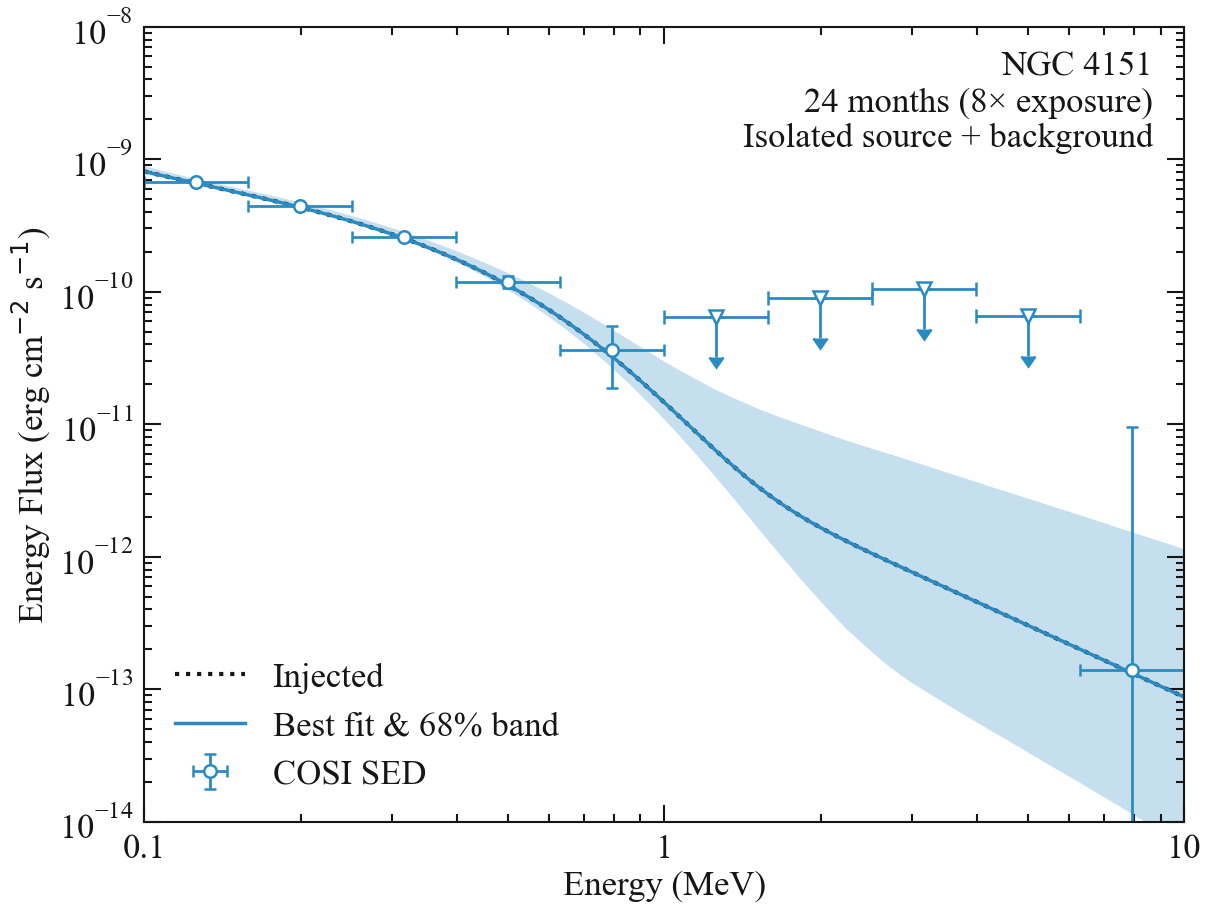

In [52]:
def plot_isolated_cpl_pl(result):
    sed = result["sed"]
    pivot = np.asarray(sed["pivot keV"])
    edges = np.asarray(sed["edges keV"])
    detected = ((sed["TS"] >= 4.) & (sed["K"] > 0.) &
                (sed["lower 68"] > 0.) & np.isfinite(sed["upper 68"]))
    upper = (~detected) & np.isfinite(sed["upper 95"]) & (sed["upper 95"] > 0.)
    plot_energy = PLOT_ENERGY_KEV
    x = plot_energy / 1000.
    fitted = result["shape"]
    with paper_style("light", FONT_SIZE):
        fig, ax = plt.subplots(figsize=(12, 9), constrained_layout=True)
        style_axis(ax, "light", FONT_SIZE)
        injected = np.asarray([spectrum_inj_isolated.evaluate_at(e) for e in plot_energy])
        ax.plot(x, KEV_TO_ERG * plot_energy**2 * injected, color=ink("light"),
                ls=":", lw=3, label="Injected")
        best = np.asarray([fitted.evaluate_at(e) for e in plot_energy])
        ax.plot(x, KEV_TO_ERG * plot_energy**2 * best, color=BLUE, lw=2.5,
                label="Best fit & 68% band")
        ax.fill_between(energy/1000.,
                        KEV_TO_ERG * energy**2 * np.where(result["low"] > 0, result["low"], np.nan),
                        KEV_TO_ERG * energy**2 * np.where(result["high"] > 0, result["high"], np.nan),
                        color=BLUE, alpha=0.27, linewidth=0)
        if np.any(detected):
            p = pivot[detected]
            k = sed["K"][detected]
            ax.errorbar(p/1000., KEV_TO_ERG*p**2*k,
                        xerr=np.vstack((p-edges[:-1][detected], edges[1:][detected]-p))/1000.,
                        yerr=np.vstack((KEV_TO_ERG*p**2*(k-sed["lower 68"][detected]),
                                        KEV_TO_ERG*p**2*(sed["upper 68"][detected]-k))),
                        fmt="o", color=BLUE, ecolor=BLUE, markerfacecolor="white",
                        markeredgewidth=1.8, markersize=9, capsize=4,
                        label="COSI SED")
        if np.any(upper):
            p = pivot[upper]
            limits = KEV_TO_ERG*p**2*sed["upper 95"][upper]
            ax.errorbar(p/1000., limits,
                        xerr=np.vstack((p-edges[:-1][upper], edges[1:][upper]-p))/1000.,
                        yerr=np.maximum(0.5*limits, np.finfo(float).tiny), uplims=True,
                        fmt="v", color=BLUE, ecolor=BLUE, markerfacecolor="white",
                        markeredgewidth=1.8, markersize=10, capsize=5)
        visible = np.r_[KEV_TO_ERG*pivot[upper]**2*sed["upper 95"][upper],
                        KEV_TO_ERG*pivot[detected]**2*sed["K"][detected]]
        ax.set(xscale="log", yscale="log", xlim=(0.1, 10.),
               ylim=(max(1e-14, 0.001*np.min(visible)) if visible.size else 1e-14,
                     max(1e-8, 2*np.max(visible)) if visible.size else 1e-9),
               xlabel="Energy (MeV)", ylabel=r"Energy Flux (erg cm$^{-2}$ s$^{-1}$)")
        ax.xaxis.set_major_locator(mticker.FixedLocator([0.1, 1., 10.]))
        ax.xaxis.set_major_formatter(mticker.FixedFormatter(["0.1", "1", "10"]))
        ax.text(0.97, 0.97, "NGC 4151\n24 months (8× exposure)\nIsolated source + background",
                transform=ax.transAxes, ha="right", va="top", fontsize=FONT_SIZE,
                color=ink("light"), bbox=dict(facecolor="white", edgecolor="none",
                                              alpha=0.78, pad=5))
        ax.legend(loc="lower left", frameon=False, fontsize=FONT_SIZE)
        PAPER_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
        pdf_path = PAPER_OUTPUT_DIR / "NGC4151_DC4_paper_isolated_cpl_pl_24months_white.pdf"
        png_path = PAPER_OUTPUT_DIR / "NGC4151_DC4_paper_isolated_cpl_pl_24months_white.png"
        fig.savefig(pdf_path, format="pdf", facecolor="white", edgecolor="white",
                    transparent=False, bbox_inches="tight")
        fig.savefig(png_path, dpi=220, facecolor="white", edgecolor="white",
                    transparent=False, bbox_inches="tight")
        print("Saved", pdf_path, "and", png_path)
        plt.show()
    return fig

isolated_figure = plot_isolated_cpl_pl(isolated_result)
